# Healthcare Stroke Dataset: Cleaning, Exploration, EDA, and Feature Engineering

This notebook is an **assignment-style TODO notebook**.  
Your goal is to explore, clean, process, and analyze the stroke dataset step by step.

**Dataset file:** `healthcare-dataset-stroke-data.csv`

### Main workflow
**Explore → Assess Data Quality → Clean → Validate → EDA → Feature Engineering → Business Questions**


In [3]:
# TODO 0: Import the main libraries you will need.
# Suggested libraries: pandas, numpy, matplotlib.pyplot, seaborn

# Your code here
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

## TODO 1 — Load and preview the dataset

Load the CSV file into a Pandas DataFrame.

Then:
- Display the first rows.
- Display the last rows.
- Identify what one row represents.
- Identify the likely target variable.

**Do not perform cleaning yet.**

In [5]:
# Your code here
df = pd.read_csv("C:/Users/ZBook G3/Downloads/projects/healthcar/data/healthcare-dataset-stroke-data.csv")
print(df.head())
print(df.tail())
print("\nOne row represents one person/patient record.")
print("The target variable is 'stroke': 1 = stroke, 0 = no stroke.")


      id  gender   age  hypertension  heart_disease ever_married  \
0   9046    Male  67.0             0              1          Yes   
1  51676  Female  61.0             0              0          Yes   
2  31112    Male  80.0             0              1          Yes   
3  60182  Female  49.0             0              0          Yes   
4   1665  Female  79.0             1              0          Yes   

       work_type Residence_type  avg_glucose_level   bmi   smoking_status  \
0        Private          Urban             228.69  36.6  formerly smoked   
1  Self-employed          Rural             202.21   NaN     never smoked   
2        Private          Rural             105.92  32.5     never smoked   
3        Private          Urban             171.23  34.4           smokes   
4  Self-employed          Rural             174.12  24.0     never smoked   

   stroke  
0       1  
1       1  
2       1  
3       1  
4       1  
         id  gender   age  hypertension  heart_disease e

## TODO 2 — Understand the dataset structure

Investigate the structure of the dataset.

Find:
- Number of rows and columns.
- Column names.
- Data types.
- Memory usage.
- `df.info()` output.

Then classify the variables into:
- Numerical
- Categorical
- Binary
- Identifier
- Target

In [7]:
# Your code here
print("Shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("dtype"))

print("\nDataset information:")
df.info()

print("\nApproximate memory usage:")
print(df.memory_usage(deep=True).sum() / 1024, "KB")

# Simple manual classification
identifier_columns = ["id"]
numerical_columns = ["age", "avg_glucose_level", "bmi"]
binary_columns = ["hypertension", "heart_disease", "stroke"]
categorical_columns = [
    "gender", "ever_married", "work_type",
    "Residence_type", "smoking_status"
]
target_column = "stroke"

print("\nIdentifier:", identifier_columns)
print("Numerical:", numerical_columns)
print("Binary:", binary_columns)
print("Categorical:", categorical_columns)
print("Target:", target_column)

Shape: (5110, 12)

Column names:
['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status', 'stroke']

Data types:


,dtype
id,int64
gender,str
age,float64
hypertension,int64
heart_disease,int64
ever_married,str
work_type,str
Residence_type,str
avg_glucose_level,float64
bmi,float64



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 479.2 KB

Approximate memory usage:
1657.6689453125 KB

Identifier: ['id']
Numerical: ['age', 'avg_glucose_level', 'bmi']
Binary: ['hypertension', 'heart_disea

## TODO 3 — Generate descriptive statistics

Generate descriptive statistics for both numerical and categorical variables.

For numerical variables, examine:
- Mean
- Median
- Standard deviation
- Minimum
- Maximum
- Quartiles

For categorical variables, examine:
- Number of unique values
- Most frequent category
- Frequency of the most frequent category

Pay special attention to:
`age`, `avg_glucose_level`, `bmi`, `hypertension`, `heart_disease`, and `stroke`.

In [8]:
# Your code here

print("Numerical statistics:")
print(df.describe())

print("\nCategorical statistics:")
print(df.describe(include="object"))

print("\nMedians of important numerical variables:")
for col in ["age", "avg_glucose_level", "bmi"]:
    print(f"{col}: {df[col].median():.2f}")

Numerical statistics:
                 id          age  hypertension  heart_disease  \
count   5110.000000  5110.000000   5110.000000    5110.000000   
mean   36517.829354    43.226614      0.097456       0.054012   
std    21161.721625    22.612647      0.296607       0.226063   
min       67.000000     0.080000      0.000000       0.000000   
25%    17741.250000    25.000000      0.000000       0.000000   
50%    36932.000000    45.000000      0.000000       0.000000   
75%    54682.000000    61.000000      0.000000       0.000000   
max    72940.000000    82.000000      1.000000       1.000000   

       avg_glucose_level          bmi       stroke  
count        5110.000000  4909.000000  5110.000000  
mean          106.147677    28.893237     0.048728  
std            45.283560     7.854067     0.215320  
min            55.120000    10.300000     0.000000  
25%            77.245000    23.500000     0.000000  
50%            91.885000    28.100000     0.000000  
75%           114.090

C:\Users\ZBook G3\AppData\Local\Temp\ipykernel_15460\71749545.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(df.describe(include="object"))


## TODO 4 — Check duplicates and the ID column

Investigate:
- Fully duplicated rows.
- Duplicate values in `id`.
- Whether `id` contains useful analytical information.

Decide whether `id` should remain as a feature in the analytical dataset and justify your decision.

In [9]:
# Your code here
duplicate_rows = df.duplicated().sum()
duplicate_ids = df["id"].duplicated().sum()
unique_ids = df["id"].nunique()

print("Fully duplicated rows:", duplicate_rows)
print("Duplicated IDs:", duplicate_ids)
print("Unique IDs:", unique_ids)
print("Total rows:", len(df))

if unique_ids == len(df):
    print("\nEvery row has a unique ID.")

print("\nDecision: 'id' will be removed from the analytical features because it is only an identifier.")



Fully duplicated rows: 0
Duplicated IDs: 0
Unique IDs: 5110
Total rows: 5110

Every row has a unique ID.

Decision: 'id' will be removed from the analytical features because it is only an identifier.


## TODO 5 — Explore categorical values

Inspect unique values and value counts for:

- `gender`
- `ever_married`
- `work_type`
- `Residence_type`
- `smoking_status`

Look for:
- Rare categories
- Unusual categories
- Inconsistent spelling
- Inconsistent capitalization
- Values such as `Unknown`

Document anything that may require cleaning or special treatment.

In [10]:
# Your code here
categorical_to_check = [
    "gender",
    "ever_married",
    "work_type",
    "Residence_type",
    "smoking_status"
]

for col in categorical_to_check:
    print("\n" + "=" * 60)
    print(f"Column: {col}")
    print("Unique values:", df[col].unique())
    print("\nCounts:")
    display(df[col].value_counts(dropna=False).to_frame("count"))



Column: gender
Unique values: <StringArray>
['Male', 'Female', 'Other']
Length: 3, dtype: str

Counts:


,count
gender,
Female,2994
Male,2115
Other,1



Column: ever_married
Unique values: <StringArray>
['Yes', 'No']
Length: 2, dtype: str

Counts:


,count
ever_married,
Yes,3353
No,1757



Column: work_type
Unique values: <StringArray>
['Private', 'Self-employed', 'Govt_job', 'children', 'Never_worked']
Length: 5, dtype: str

Counts:


,count
work_type,
Private,2925
Self-employed,819
children,687
Govt_job,657
Never_worked,22



Column: Residence_type
Unique values: <StringArray>
['Urban', 'Rural']
Length: 2, dtype: str

Counts:


,count
Residence_type,
Urban,2596
Rural,2514



Column: smoking_status
Unique values: <StringArray>
['formerly smoked', 'never smoked', 'smokes', 'Unknown']
Length: 4, dtype: str

Counts:


,count
smoking_status,
never smoked,1892
Unknown,1544
formerly smoked,885
smokes,789


## TODO 6 — Investigate missing values

Calculate:
- Number of missing values in every column.
- Percentage of missing values in every column.

Create a clear summary showing which variables contain missing data.

Identify the feature with the largest missing-value issue.

In [11]:
# Your code here
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": df.isna().mean() * 100
}).sort_values("missing_count", ascending=False)

print(missing_summary)

largest_missing_col = missing_summary.index[0]

print(
    f"\nThe column with the most missing values is '{largest_missing_col}' "
    f"with {missing_summary.loc[largest_missing_col, 'missing_count']:.0f} missing values."
)


                   missing_count  missing_percent
bmi                          201         3.933464
id                             0         0.000000
age                            0         0.000000
gender                         0         0.000000
hypertension                   0         0.000000
heart_disease                  0         0.000000
work_type                      0         0.000000
ever_married                   0         0.000000
Residence_type                 0         0.000000
avg_glucose_level              0         0.000000
smoking_status                 0         0.000000
stroke                         0         0.000000

The column with the most missing values is 'bmi' with 201 missing values.


## TODO 7 — Handle missing BMI values

Study the distribution of `bmi` before imputing missing values.

Compare possible strategies such as:
- Mean imputation
- Median imputation
- Group-based median imputation

Choose one strategy and justify it.

Then apply the selected method and verify that the missing BMI values were handled correctly.

BMI mean: 28.89
BMI median: 28.10
BMI skewness: 1.06
Missing BMI before imputation: 201


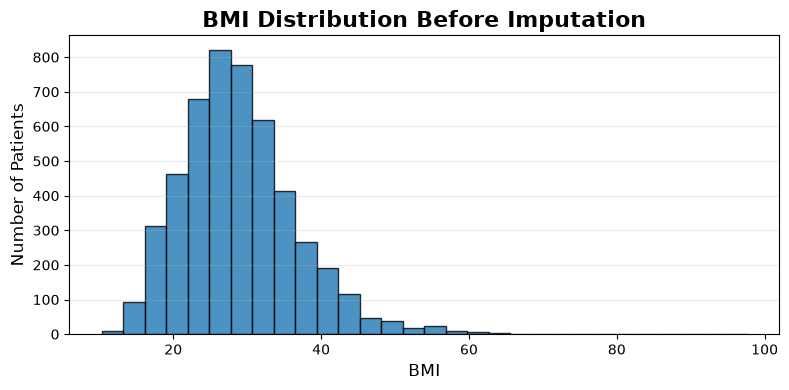

Missing BMI after imputation: 0

Decision: Missing BMI values were replaced with the dataset median.


In [19]:
# Your code here
bmi_mean = df["bmi"].mean()
bmi_median = df["bmi"].median()
bmi_skewness = df["bmi"].skew()

print(f"BMI mean: {bmi_mean:.2f}")
print(f"BMI median: {bmi_median:.2f}")
print(f"BMI skewness: {bmi_skewness:.2f}")
print("Missing BMI before imputation:", df["bmi"].isna().sum())

plt.figure(figsize=(8, 4))

plt.hist(
    df["bmi"].dropna(),
    bins=30,
    edgecolor="black",
    alpha=0.8
)

plt.title("BMI Distribution Before Imputation", fontsize=16, fontweight="bold")
plt.xlabel("BMI", fontsize=12)
plt.ylabel("Number of Patients", fontsize=12)

plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig(
    "C:/Users/ZBook G3/Downloads/projects/healthcar/images/bmi_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Work on a copy so we preserve the raw dataframe
df_clean = df.copy()

# Median imputation
df_clean["bmi"] = df_clean["bmi"].fillna(bmi_median)

print("Missing BMI after imputation:", df_clean["bmi"].isna().sum())
print("\nDecision: Missing BMI values were replaced with the dataset median.")



## TODO 8 — Handle unusual categorical values

Investigate categories such as:

- `gender = Other`
- `smoking_status = Unknown`

For each one:
- Count how many observations belong to the category.
- Calculate its percentage of the dataset.
- Decide whether it should be retained, grouped, removed, or handled separately.

**Important:** Do not automatically treat `Unknown` as a missing value without investigation.

In [22]:
# Your code here
other_gender_count = (df_clean["gender"] == "Other").sum()
other_gender_percent = (df_clean["gender"] == "Other").mean() * 100

unknown_smoking_count = (df_clean["smoking_status"] == "Unknown").sum()
unknown_smoking_percent = (df_clean["smoking_status"] == "Unknown").mean() * 100

print(f"'Other' gender: {other_gender_count} row(s), {other_gender_percent:.3f}%")
print(f"'Unknown' smoking status: {unknown_smoking_count} rows, {unknown_smoking_percent:.2f}%")

print("\nDecision:")
print("- Retain 'Other'.")
print("- Retain 'Unknown' as a separate smoking-status category.")


'Other' gender: 1 row(s), 0.020%
'Unknown' smoking status: 1544 rows, 30.22%

Decision:
- Retain 'Other'.
- Retain 'Unknown' as a separate smoking-status category.


## TODO 9 — Validate numerical ranges and detect potential outliers

Analyze potential outliers in:

- `age`
- `bmi`
- `avg_glucose_level`

Use:
- Histograms
- Boxplots
- IQR-based calculations

For each suspicious value, decide whether it looks like:
- A plausible extreme observation
- A possible data-entry error

Do not remove observations simply because they are statistical outliers.

IQR Outlier Summary:
             feature      Q1      Q3     IQR  lower_bound  upper_bound  \
0                age  25.000   61.00  36.000     -29.0000     115.0000   
1                bmi  23.800   32.80   9.000      10.3000      46.3000   
2  avg_glucose_level  77.245  114.09  36.845      21.9775     169.3575   

   potential_outliers  
0                   0  
1                 126  
2                 627  


C:\Users\ZBook G3\AppData\Local\Temp\ipykernel_15460\39671141.py:34: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


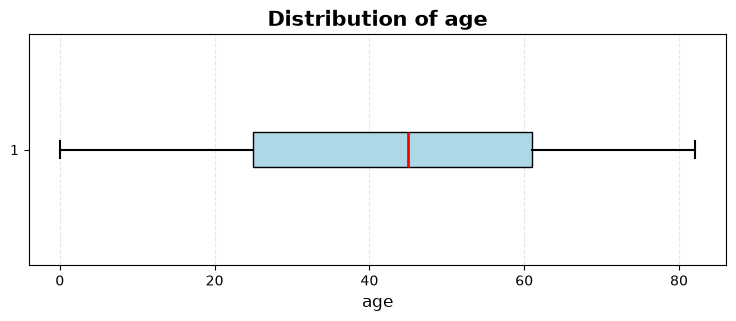

C:\Users\ZBook G3\AppData\Local\Temp\ipykernel_15460\39671141.py:34: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


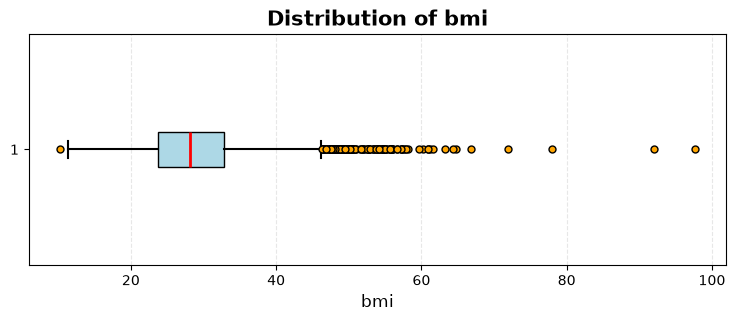

C:\Users\ZBook G3\AppData\Local\Temp\ipykernel_15460\39671141.py:34: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


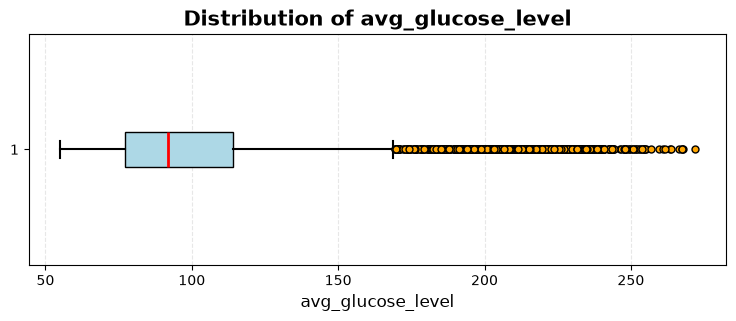


Decision:
Potential outliers were retained because statistical outliers are not automatically data-entry errors.
Values should only be removed if they are clearly outside a plausible real-world range.


In [24]:
# Your code here
outlier_rows = []

for col in ["age", "bmi", "avg_glucose_level"]:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = ((df_clean[col] < lower) | (df_clean[col] > upper)).sum()

    outlier_rows.append({
        "feature": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower_bound": lower,
        "upper_bound": upper,
        "potential_outliers": count
    })

outlier_summary = pd.DataFrame(outlier_rows)

print("IQR Outlier Summary:")
print(outlier_summary)


for col in ["age", "bmi", "avg_glucose_level"]:

    plt.figure(figsize=(9, 3))

    plt.boxplot(
        df_clean[col].dropna(),
        vert=False,
        patch_artist=True,
        boxprops=dict(facecolor="lightblue", edgecolor="black"),
        medianprops=dict(color="red", linewidth=2),
        whiskerprops=dict(color="black", linewidth=1.5),
        capprops=dict(color="black", linewidth=1.5),
        flierprops=dict(
            marker="o",
            markerfacecolor="orange",
            markeredgecolor="black",
            markersize=5
        )
    )

    plt.title(
        f"Distribution of {col}",
        fontsize=15,
        fontweight="bold"
    )

    plt.xlabel(
        col,
        fontsize=12
    )

    plt.grid(
        axis="x",
        linestyle="--",
        alpha=0.3
    )

    plt.savefig(
        f"C:/Users/ZBook G3/Downloads/projects/healthcar/images/boxplot_{col}.png",
        dpi=300,
        bbox_inches="tight"
)

    plt.show()


print("\nDecision:")
print("Potential outliers were retained because statistical outliers are not automatically data-entry errors.")
print("Values should only be removed if they are clearly outside a plausible real-world range.")

## TODO 10 — Create the cleaned analytical dataset

Apply all cleaning decisions from the previous TODOs.

Create a cleaned copy named something like:

`df_clean`

Then verify:
- Missing values
- Duplicate rows
- Data types
- Column names
- Final number of rows and columns

Summarize every cleaning operation you performed.

In [27]:
# Your code here
#Standardize column names
df_clean.columns = (
    df_clean.columns
    .str.strip()
    .str.lower()
)

# Remove ID
df_clean = df_clean.drop(columns="id")

print("Final shape:", df_clean.shape)
print("Duplicate rows:", df_clean.duplicated().sum())
print("Total missing values:", df_clean.isna().sum().sum())

print("\nMissing values by column:")
display(df_clean.isna().sum().to_frame("missing"))

print("\nData types:")
display(df_clean.dtypes.to_frame("dtype"))

print("\nFirst rows of the cleaned dataset:")
display(df_clean.head())

print("\nCleaning summary:")
print("1. BMI missing values -> median imputation.")
print("2. 'Other' gender -> retained.")
print("3. 'Unknown' smoking status -> retained as its own category.")
print("4. Potential numerical outliers -> inspected but retained.")
print("5. ID -> removed.")
print("6. Column names -> standardized to lowercase.")


Final shape: (5110, 11)
Duplicate rows: 0
Total missing values: 0

Missing values by column:


,missing
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
residence_type,0
avg_glucose_level,0
bmi,0
smoking_status,0



Data types:


,dtype
gender,str
age,float64
hypertension,int64
heart_disease,int64
ever_married,str
work_type,str
residence_type,str
avg_glucose_level,float64
bmi,float64
smoking_status,str



First rows of the cleaned dataset:


,gender,age,hypertension,heart_disease,ever_married,work_type,residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,28.1,never smoked,1
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1



Cleaning summary:
1. BMI missing values -> median imputation.
2. 'Other' gender -> retained.
3. 'Unknown' smoking status -> retained as its own category.
4. Potential numerical outliers -> inspected but retained.
5. ID -> removed.
6. Column names -> standardized to lowercase.


## TODO 11 — Explore numerical feature distributions

Perform univariate EDA for:

- `age`
- `bmi`
- `avg_glucose_level`

Use appropriate plots such as:
- Histograms
- KDE plots
- Boxplots

For each feature, comment on:
- Shape of the distribution
- Center
- Spread
- Skewness
- Possible extreme values


Feature: age
Mean: 43.23
Median: 45.00
Standard deviation: 22.61
Skewness: -0.14
Minimum: 0.08
Maximum: 82.00


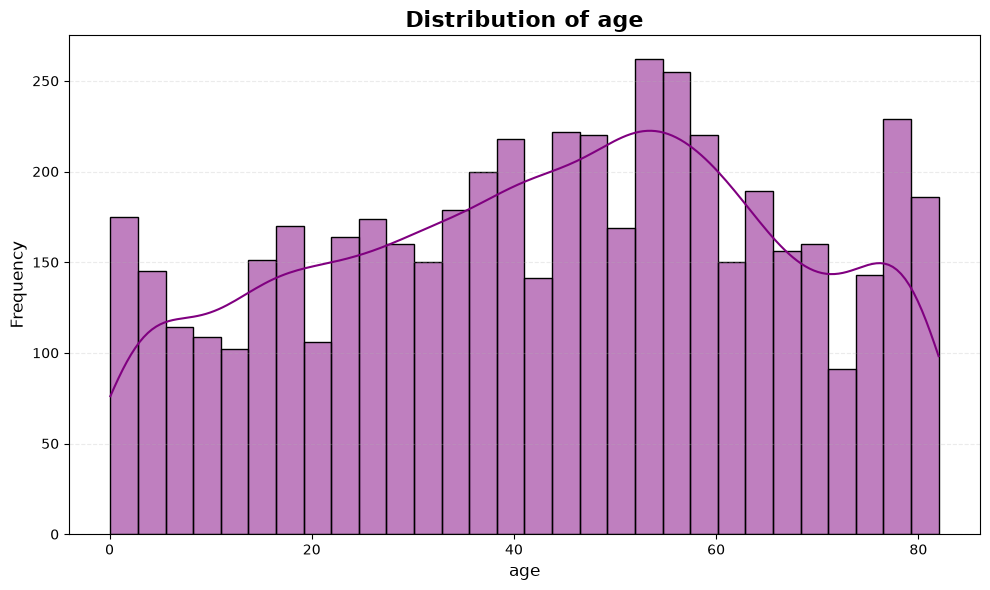

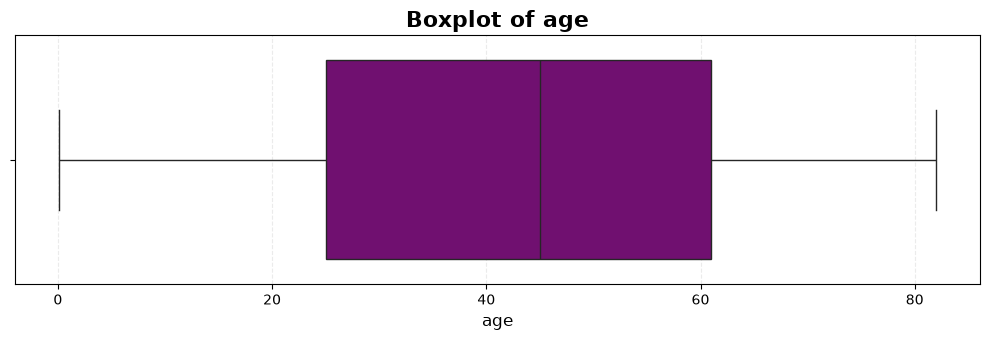


Feature: bmi
Mean: 28.86
Median: 28.10
Standard deviation: 7.70
Skewness: 1.09
Minimum: 10.30
Maximum: 97.60


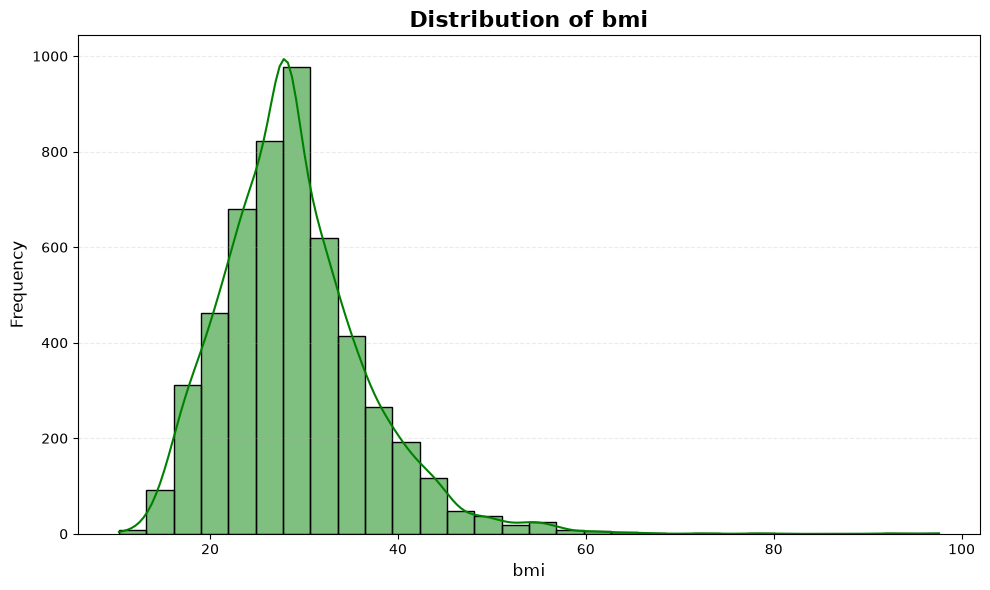

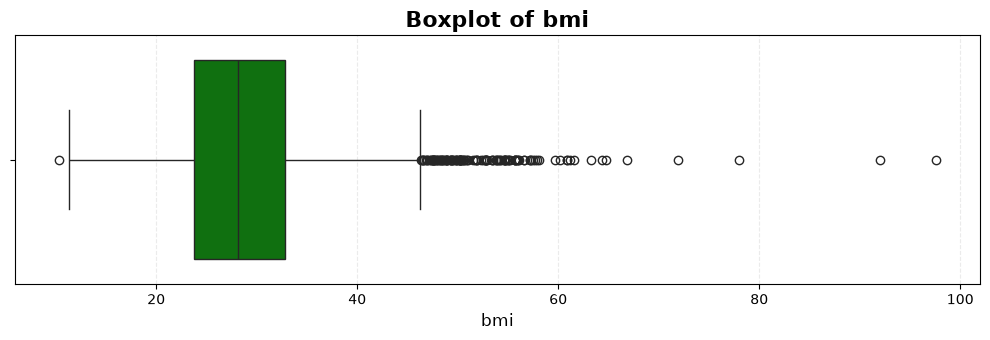


Feature: avg_glucose_level
Mean: 106.15
Median: 91.88
Standard deviation: 45.28
Skewness: 1.57
Minimum: 55.12
Maximum: 271.74


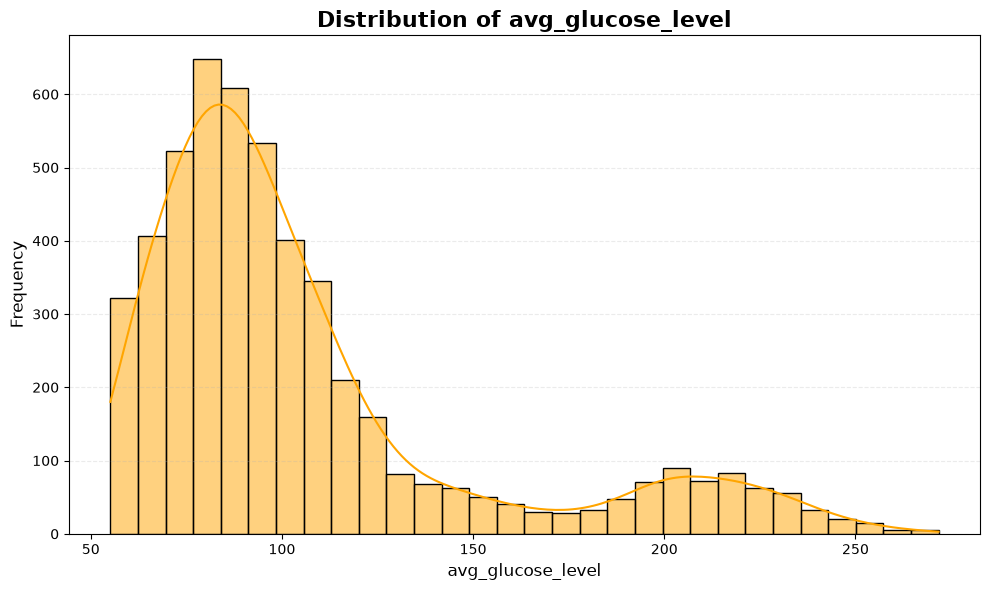

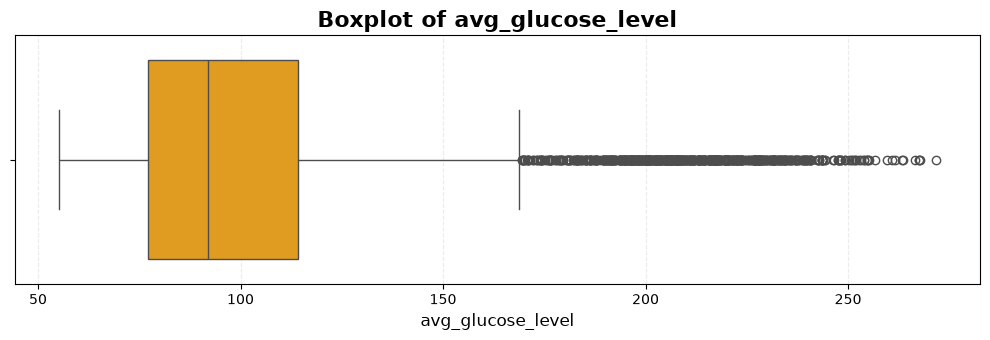

In [36]:
# Your code here
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

image_folder = Path("C:/Users/ZBook G3/Downloads/projects/healthcar/images")
image_folder.mkdir(parents=True, exist_ok=True)

numerical_features = ["age", "bmi", "avg_glucose_level"]

colors = {
    "age": "purple",
    "bmi": "green",
    "avg_glucose_level": "orange"
}

for col in numerical_features:

    # Statistics
    print("\n" + "=" * 50)
    print(f"Feature: {col}")
    print(f"Mean: {df_clean[col].mean():.2f}")
    print(f"Median: {df_clean[col].median():.2f}")
    print(f"Standard deviation: {df_clean[col].std():.2f}")
    print(f"Skewness: {df_clean[col].skew():.2f}")
    print(f"Minimum: {df_clean[col].min():.2f}")
    print(f"Maximum: {df_clean[col].max():.2f}")

    # Histogram + KDE
    plt.figure(figsize=(10, 6))

    sns.histplot(
        df_clean[col].dropna(),
        bins=30,
        kde=True,
        color=colors[col]
    )

    plt.title(
        f"Distribution of {col}",
        fontsize=16,
        fontweight="bold"
    )
    plt.xlabel(col, fontsize=12)
    plt.ylabel("Frequency", fontsize=12)

    plt.grid(
        axis="y",
        linestyle="--",
        alpha=0.25
    )

    plt.tight_layout()

    plt.savefig(
        f"C:/Users/ZBook G3/Downloads/projects/healthcar/images/{col}_distribution.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    # Boxplot
    plt.figure(figsize=(10, 3.5))

    sns.boxplot(
        x=df_clean[col].dropna(),
        color=colors[col]
    )

    plt.title(
        f"Boxplot of {col}",
        fontsize=16,
        fontweight="bold"
    )
    plt.xlabel(col, fontsize=12)

    plt.grid(
        axis="x",
        linestyle="--",
        alpha=0.25
    )

    plt.tight_layout()

    plt.savefig(
        f"C:/Users/ZBook G3/Downloads/projects/healthcar/images/{col}_boxplot.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

## TODO 12 — Explore categorical feature distributions

Visualize the distributions of important categorical/binary variables such as:

- Gender
- Work type
- Smoking status
- Residence type
- Hypertension
- Heart disease

Choose appropriate count plots or bar charts.

Do not create plots without interpretation. Write at least one useful observation for each major visualization.


Feature: gender
        count
gender       
Female   2994
Male     2115
Other       1


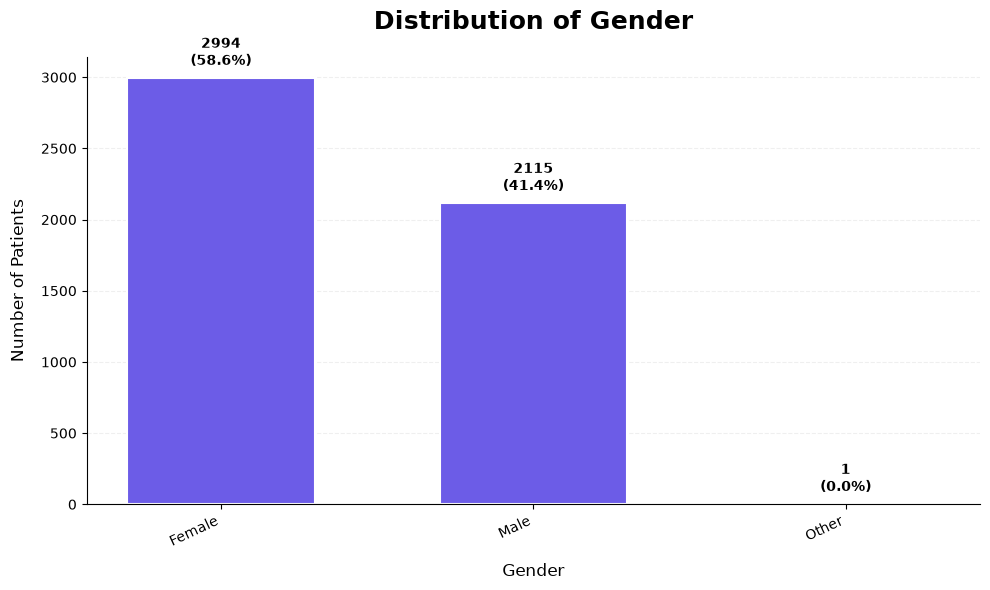


Feature: work_type
               count
work_type           
Private         2925
Self-employed    819
children         687
Govt_job         657
Never_worked      22


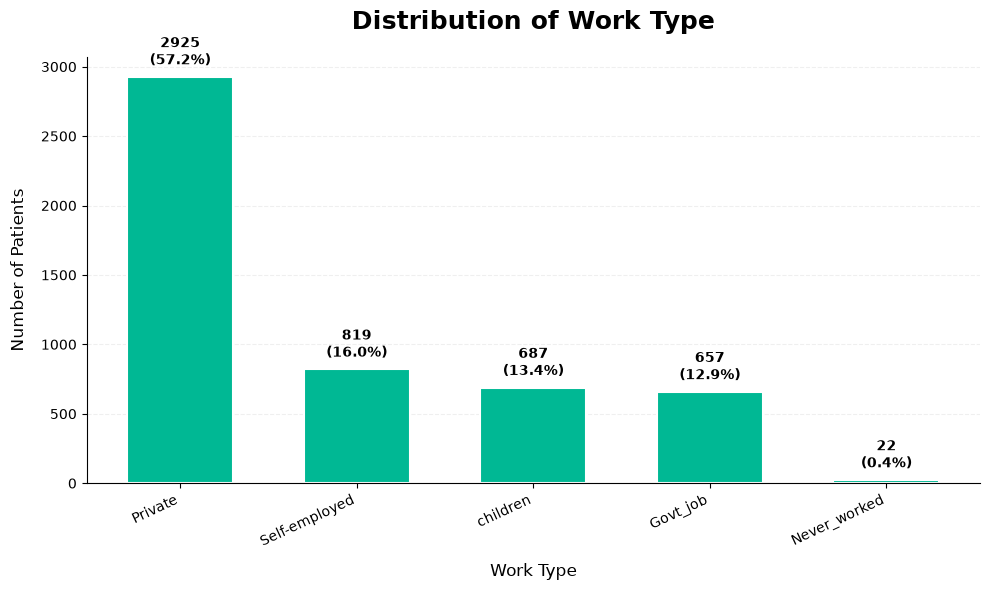


Feature: smoking_status
                 count
smoking_status        
never smoked      1892
Unknown           1544
formerly smoked    885
smokes             789


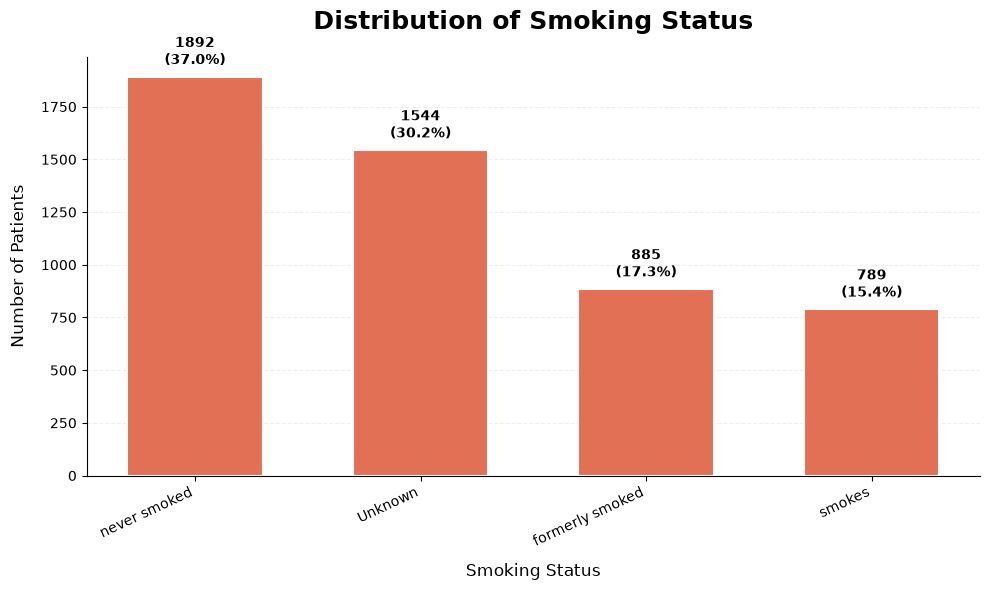


Feature: residence_type
                count
residence_type       
Urban            2596
Rural            2514


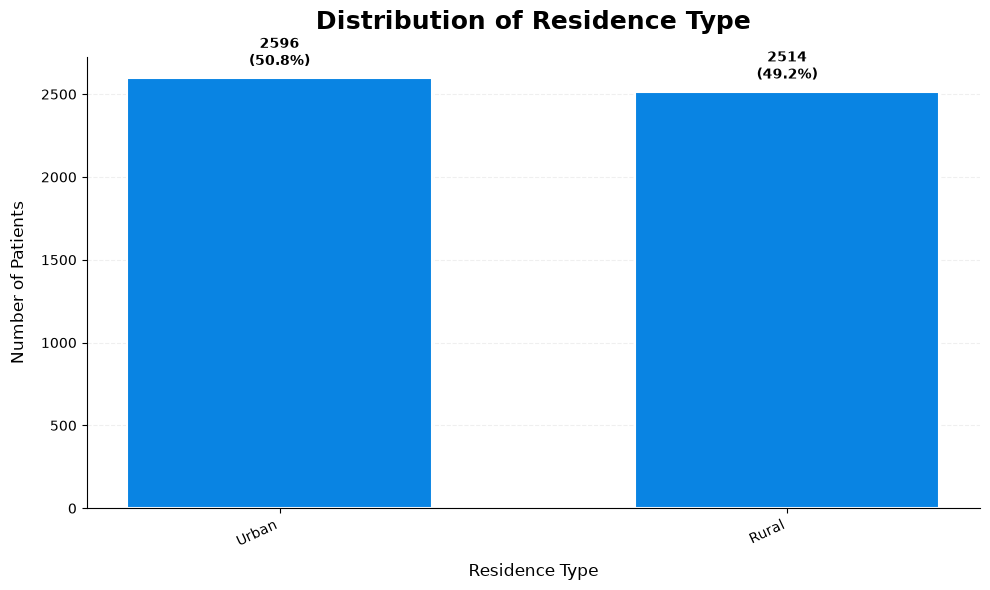


Feature: hypertension
              count
hypertension       
0              4612
1               498


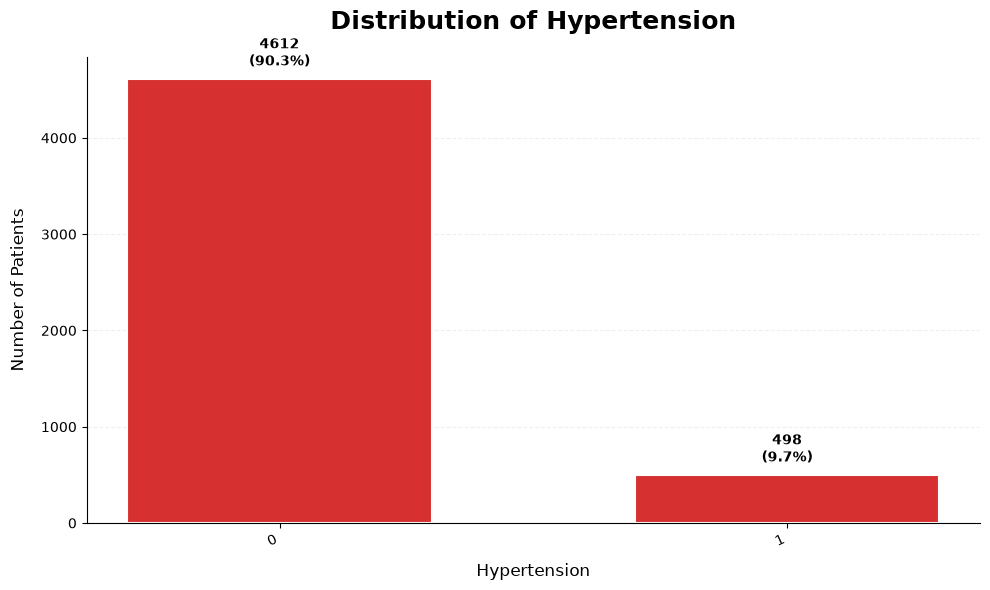


Feature: heart_disease
               count
heart_disease       
0               4834
1                276


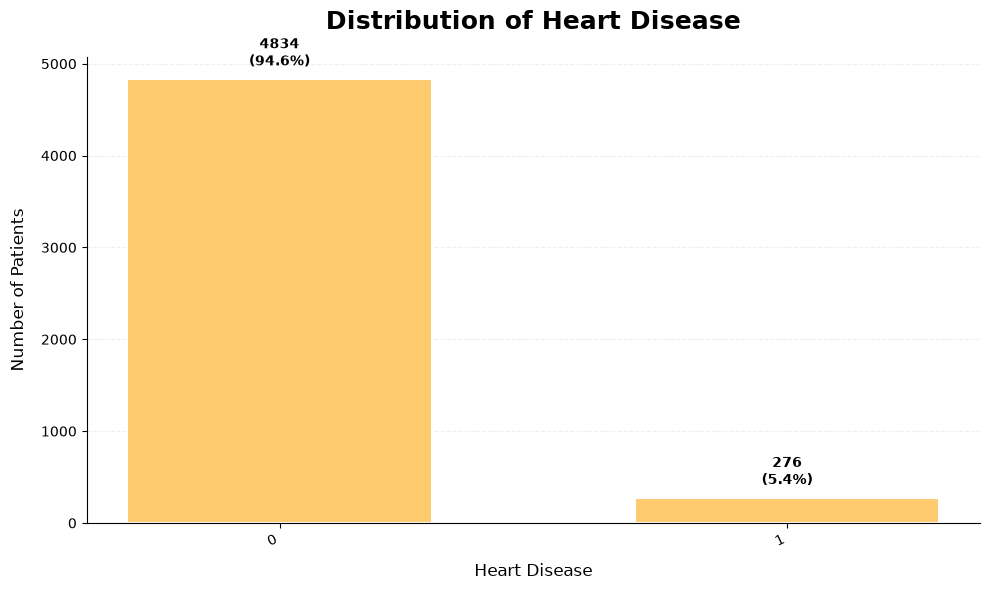

In [32]:
# Your code here
import matplotlib.pyplot as plt
from pathlib import Path

image_folder = Path(
    "C:/Users/ZBook G3/Downloads/projects/healthcar/images"
)

image_folder.mkdir(parents=True, exist_ok=True)

categorical_features = [
    "gender",
    "work_type",
    "smoking_status",
    "residence_type",
    "hypertension",
    "heart_disease"
]

colors = [
    "#6C5CE7",
    "#00B894",
    "#E17055",
    "#0984E3",
    "#D63031",
    "#FDCB6E"
]

for col, color in zip(categorical_features, colors):

    counts = df_clean[col].value_counts()
    percentages = counts / counts.sum() * 100

    print("\n" + "=" * 50)
    print(f"Feature: {col}")
    print(counts.to_frame("count"))

    # Create figure
    fig, ax = plt.subplots(figsize=(10, 6))

    bars = ax.bar(
        counts.index.astype(str),
        counts.values,
        width=0.6,
        color=color,
        edgecolor="white",
        linewidth=1.5
    )

    # Title
    ax.set_title(
        f"Distribution of {col.replace('_', ' ').title()}",
        fontsize=18,
        fontweight="bold",
        pad=20
    )

    ax.set_xlabel(
        col.replace("_", " ").title(),
        fontsize=12,
        labelpad=10
    )

    ax.set_ylabel(
        "Number of Patients",
        fontsize=12,
        labelpad=10
    )

    # Remove top and right borders
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # Light grid
    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.2
    )

    ax.set_axisbelow(True)

    # Rotate labels if needed
    plt.xticks(
        rotation=25,
        ha="right",
        fontsize=10
    )

    # Add count + percentage above each bar
    for bar, percentage in zip(bars, percentages):

        height = bar.get_height()

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height + counts.max() * 0.02,
            f"{int(height)}\n({percentage:.1f}%)",
            ha="center",
            va="bottom",
            fontsize=10,
            fontweight="bold"
        )

    plt.tight_layout()

    plt.savefig(
        image_folder / f"{col}_distribution.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

## TODO 13 — Investigate the target variable

Analyze the distribution of `stroke`.

Calculate:
- Number of stroke cases.
- Number of non-stroke cases.
- Percentage of each class.

Create a visualization.

Then discuss:
- Whether the target is balanced.
- Why class imbalance matters when interpreting results or later building a machine-learning model.

Stroke Target Summary:
               count    percent
No Stroke (0)   4861  95.127202
Stroke (1)       249   4.872798


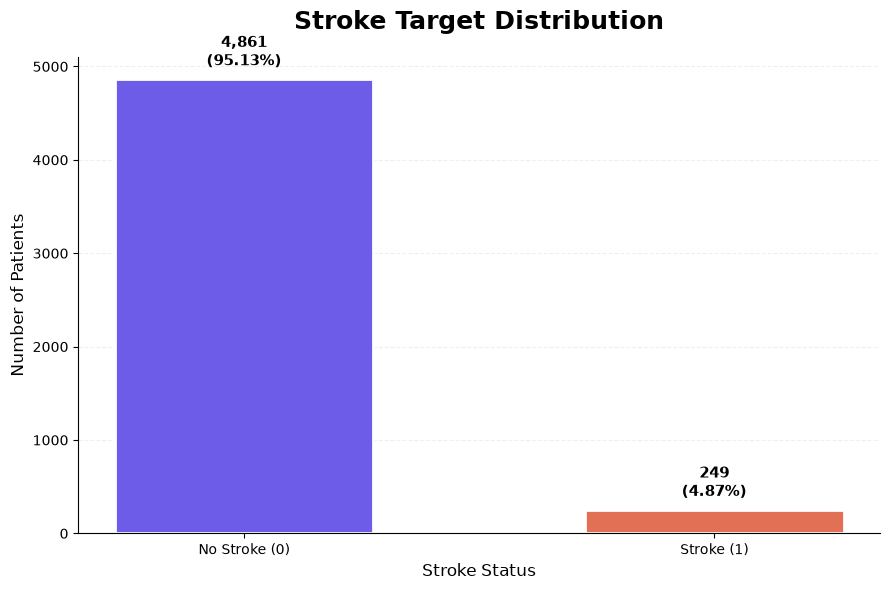


Stroke cases represent 4.87% of the dataset.
Therefore, the target variable is strongly imbalanced.
Accuracy alone may not be sufficient for evaluating a machine-learning model because the minority class is small.


In [37]:
# Your code here
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Create images folder
image_folder = Path(
    "C:/Users/ZBook G3/Downloads/projects/healthcar/images"
)

image_folder.mkdir(parents=True, exist_ok=True)


# Calculate counts
stroke_counts = (
    df_clean["stroke"]
    .value_counts()
    .sort_index()
)

# Calculate percentages
stroke_percent = (
    df_clean["stroke"]
    .value_counts(normalize=True)
    .sort_index() * 100
)


# Create summary table
target_summary = pd.DataFrame({
    "count": stroke_counts,
    "percent": stroke_percent
})

target_summary.index = [
    "No Stroke (0)",
    "Stroke (1)"
]


# Display summary
print("Stroke Target Summary:")
print(target_summary)


# Create visualization
plt.figure(figsize=(9, 6))

bars = plt.bar(
    target_summary.index,
    target_summary["count"],
    width=0.55,
    color=["#6C5CE7", "#E17055"],
    edgecolor="white",
    linewidth=2
)


# Title and labels
plt.title(
    "Stroke Target Distribution",
    fontsize=18,
    fontweight="bold",
    pad=20
)

plt.xlabel(
    "Stroke Status",
    fontsize=12
)

plt.ylabel(
    "Number of Patients",
    fontsize=12
)


# Remove unnecessary borders
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)


# Add light grid
plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.2
)

plt.gca().set_axisbelow(True)


# Add count and percentage above each bar
for bar, count, percent in zip(
    bars,
    target_summary["count"],
    target_summary["percent"]
):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + target_summary["count"].max() * 0.02,
        f"{count:,}\n({percent:.2f}%)",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )


plt.tight_layout()


# Save the figure
plt.savefig(
    image_folder / "stroke_target_distribution.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()


# Conclusion
print(
    f"\nStroke cases represent {stroke_percent.loc[1]:.2f}% "
    "of the dataset."
)

print(
    "Therefore, the target variable is strongly imbalanced."
)

print(
    "Accuracy alone may not be sufficient for evaluating "
    "a machine-learning model because the minority class is small."
)

## TODO 14 — Compare stroke rates across categorical groups

For several categorical variables, calculate **stroke rate**, not only raw stroke counts.

Suggested variables:
- Gender
- Hypertension
- Heart disease
- Smoking status
- Work type
- Residence type
- Marital status

Use:

**Stroke Rate = Stroke Cases / Total People in the Group**

Visualize selected group-level stroke rates and identify noticeable differences.


Stroke Rate by gender
        people  stroke_cases  stroke_rate  stroke_rate_percent
gender                                                        
Male      2115           108     0.051064             5.106383
Female    2994           141     0.047094             4.709419
Other        1             0     0.000000             0.000000


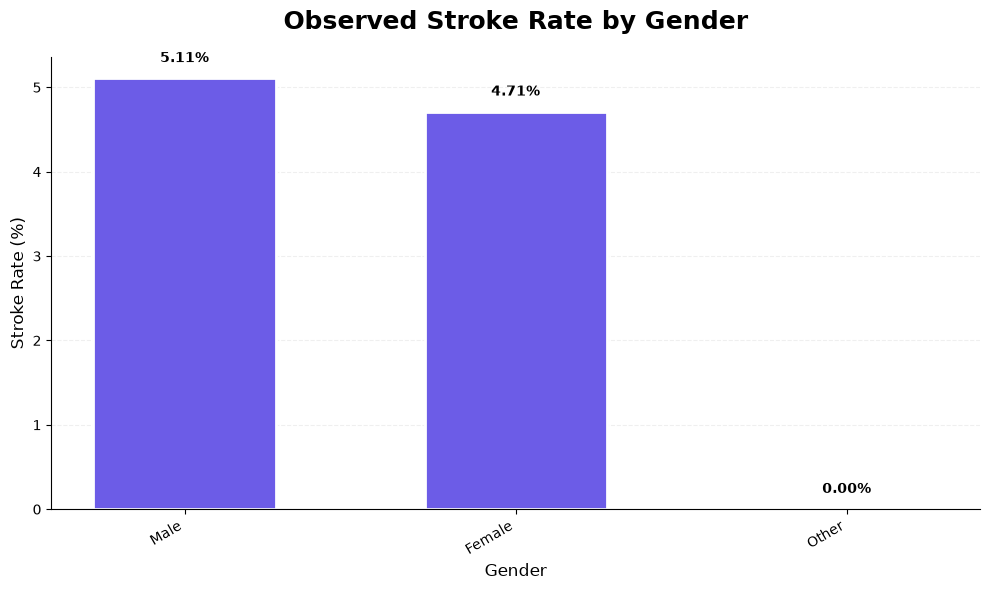


Stroke Rate by hypertension
              people  stroke_cases  stroke_rate  stroke_rate_percent
hypertension                                                        
1                498            66     0.132530            13.253012
0               4612           183     0.039679             3.967910


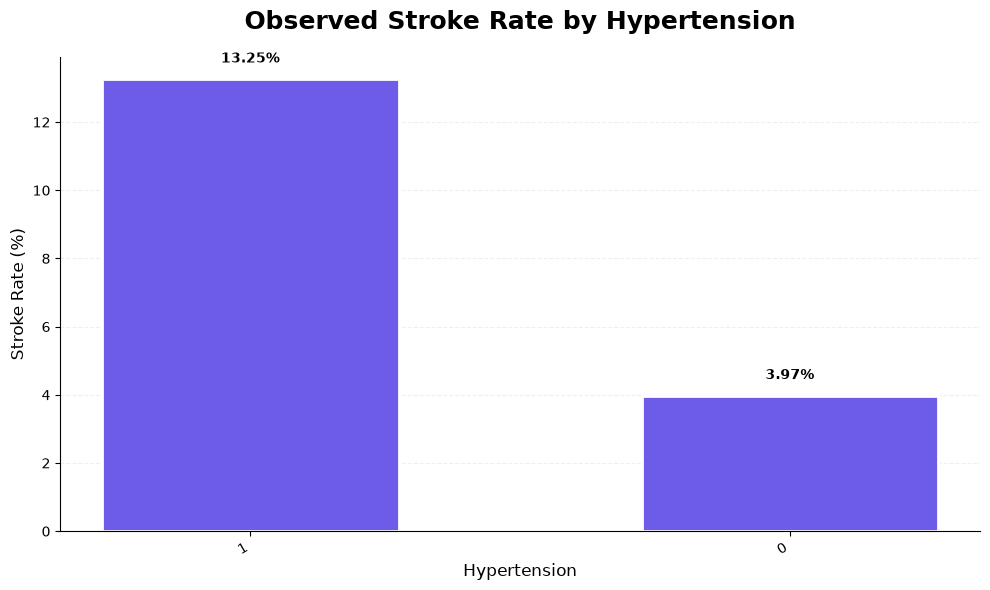


Stroke Rate by heart_disease
               people  stroke_cases  stroke_rate  stroke_rate_percent
heart_disease                                                        
1                 276            47     0.170290            17.028986
0                4834           202     0.041787             4.178734


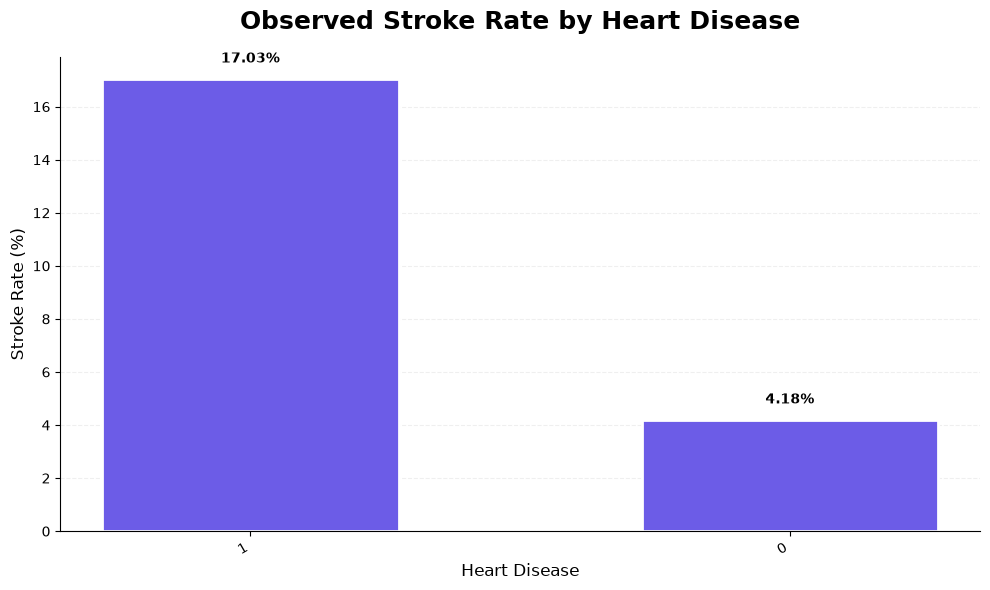


Stroke Rate by smoking_status
                 people  stroke_cases  stroke_rate  stroke_rate_percent
smoking_status                                                         
formerly smoked     885            70     0.079096             7.909605
smokes              789            42     0.053232             5.323194
never smoked       1892            90     0.047569             4.756871
Unknown            1544            47     0.030440             3.044041


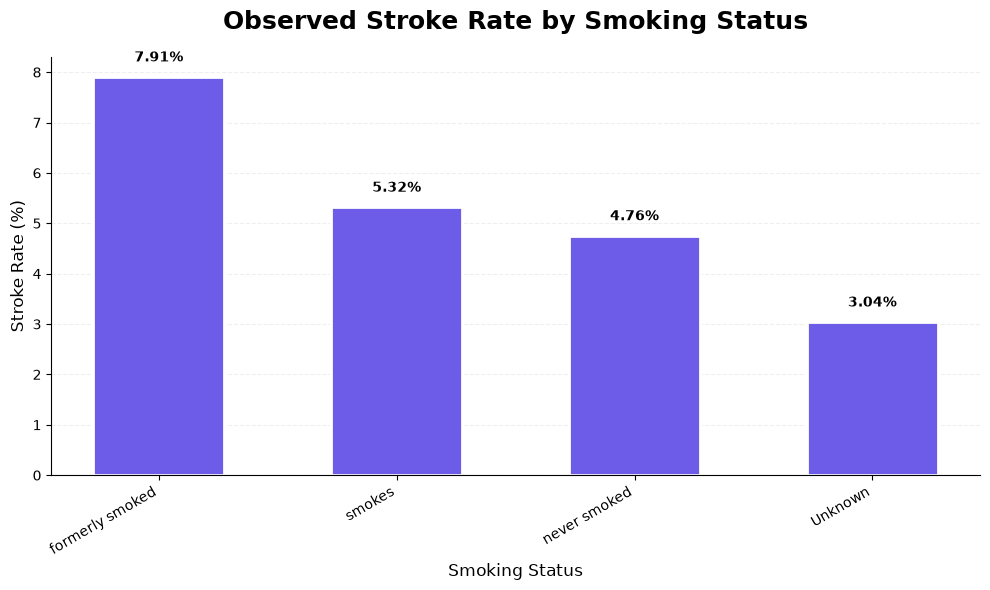


Stroke Rate by work_type
               people  stroke_cases  stroke_rate  stroke_rate_percent
work_type                                                            
Self-employed     819            65     0.079365             7.936508
Private          2925           149     0.050940             5.094017
Govt_job          657            33     0.050228             5.022831
children          687             2     0.002911             0.291121
Never_worked       22             0     0.000000             0.000000


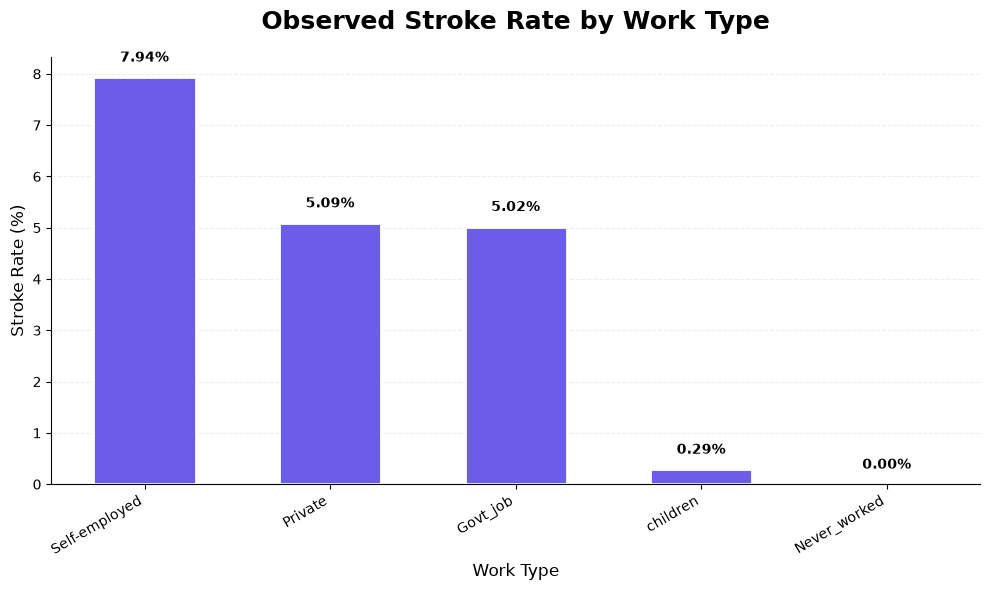


Stroke Rate by residence_type
                people  stroke_cases  stroke_rate  stroke_rate_percent
residence_type                                                        
Urban             2596           135     0.052003             5.200308
Rural             2514           114     0.045346             4.534606


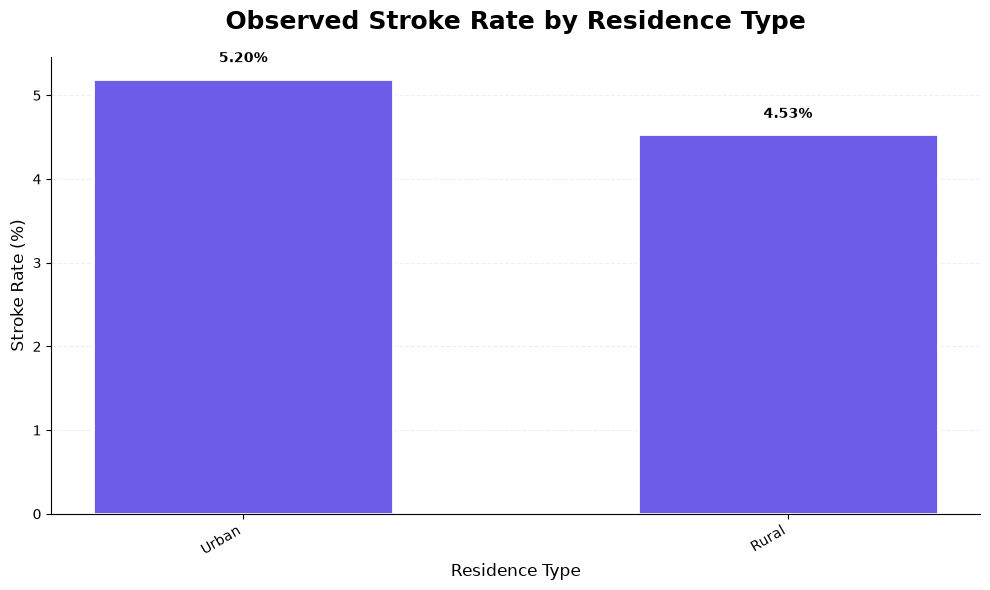


Stroke Rate by ever_married
              people  stroke_cases  stroke_rate  stroke_rate_percent
ever_married                                                        
Yes             3353           220     0.065613             6.561288
No              1757            29     0.016505             1.650541


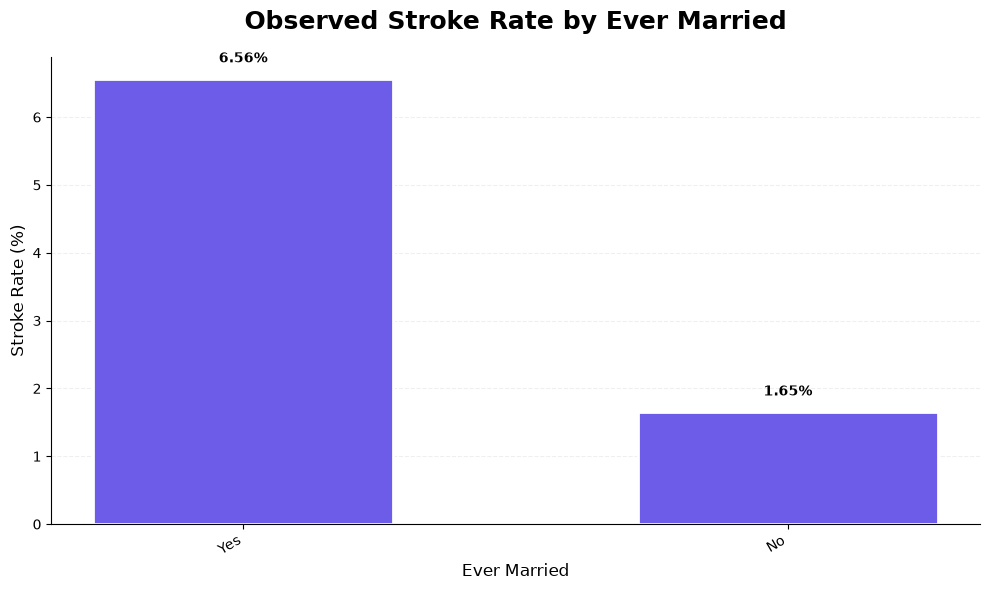

In [ ]:
# Your code here
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path


# Create images folder
image_folder = Path(
    "C:/Users/ZBook G3/Downloads/projects/healthcar/images"
)

image_folder.mkdir(parents=True, exist_ok=True)


# Categorical variables
group_features = [
    "gender",
    "hypertension",
    "heart_disease",
    "smoking_status",
    "work_type",
    "residence_type",
    "ever_married"
]


# Store stroke rate tables
stroke_rate_tables = {}


for col in group_features:

    # Calculate group statistics
    summary = (
        df_clean.groupby(col, observed=True)
        .agg(
            people=("stroke", "size"),
            stroke_cases=("stroke", "sum"),
            stroke_rate=("stroke", "mean")
        )
        .sort_values(
            "stroke_rate",
            ascending=False
        )
    )

    # Convert stroke rate to percentage
    summary["stroke_rate_percent"] = (
        summary["stroke_rate"] * 100
    )

    # Store table
    stroke_rate_tables[col] = summary


    # Print results
    print("\n" + "=" * 60)
    print(f"Stroke Rate by {col}")
    print("=" * 60)

    print(summary)


    # -----------------------------
    # Visualization
    # -----------------------------

    plt.figure(figsize=(10, 6))

    bars = plt.bar(
        summary.index.astype(str),
        summary["stroke_rate_percent"],
        width=0.55,
        color="#6C5CE7",
        edgecolor="white",
        linewidth=2
    )


    # Title
    plt.title(
        f"Observed Stroke Rate by {col.replace('_', ' ').title()}",
        fontsize=18,
        fontweight="bold",
        pad=20
    )


    # Axis labels
    plt.xlabel(
        col.replace("_", " ").title(),
        fontsize=12
    )

    plt.ylabel(
        "Stroke Rate (%)",
        fontsize=12
    )


    # Remove top and right borders
    plt.gca().spines["top"].set_visible(False)
    plt.gca().spines["right"].set_visible(False)


    # Add light grid
    plt.grid(
        axis="y",
        linestyle="--",
        alpha=0.2
    )

    plt.gca().set_axisbelow(True)


    # Rotate category labels
    plt.xticks(
        rotation=30,
        ha="right"
    )


    # Add percentage labels
    for bar, rate in zip(
        bars,
        summary["stroke_rate_percent"]
    ):

        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + summary["stroke_rate_percent"].max() * 0.03,
            f"{rate:.2f}%",
            ha="center",
            va="bottom",
            fontsize=10,
            fontweight="bold"
        )


    plt.tight_layout()


    # Save figure
    plt.savefig(
        image_folder / f"stroke_rate_by_{col}.png",
        dpi=300,
        bbox_inches="tight"
    )


    plt.show()
    

## TODO 15 — Compare numerical features by stroke status

Compare the following features between people with and without stroke:

- `age`
- `bmi`
- `avg_glucose_level`

Use appropriate visualizations such as:
- Boxplots
- Histograms
- KDE plots

Also calculate grouped summary statistics.

Discuss which numerical variables appear most associated with stroke occurrence in this dataset.

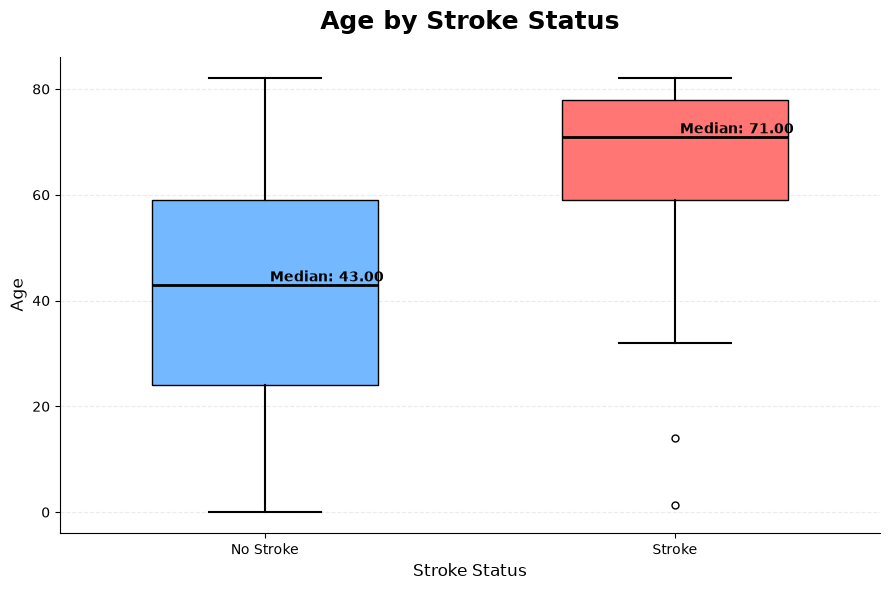

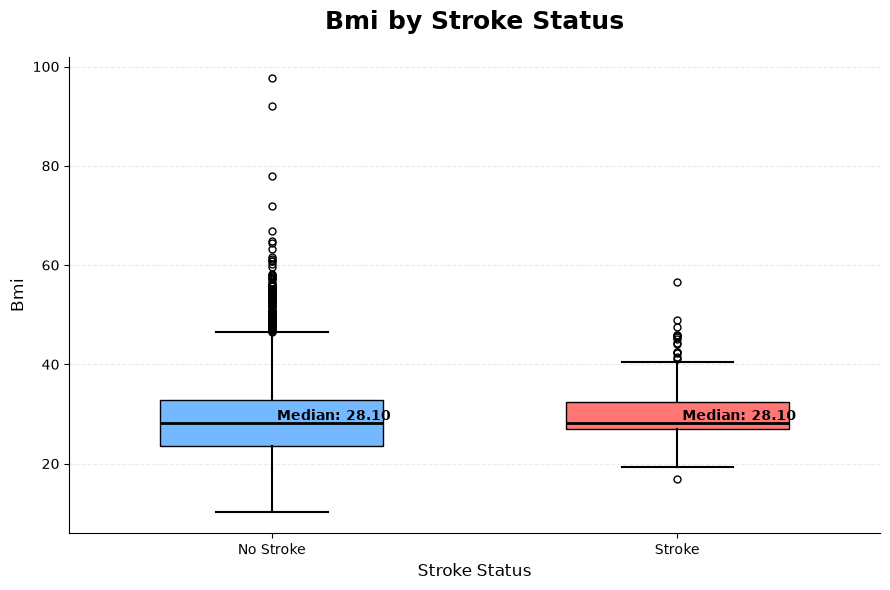

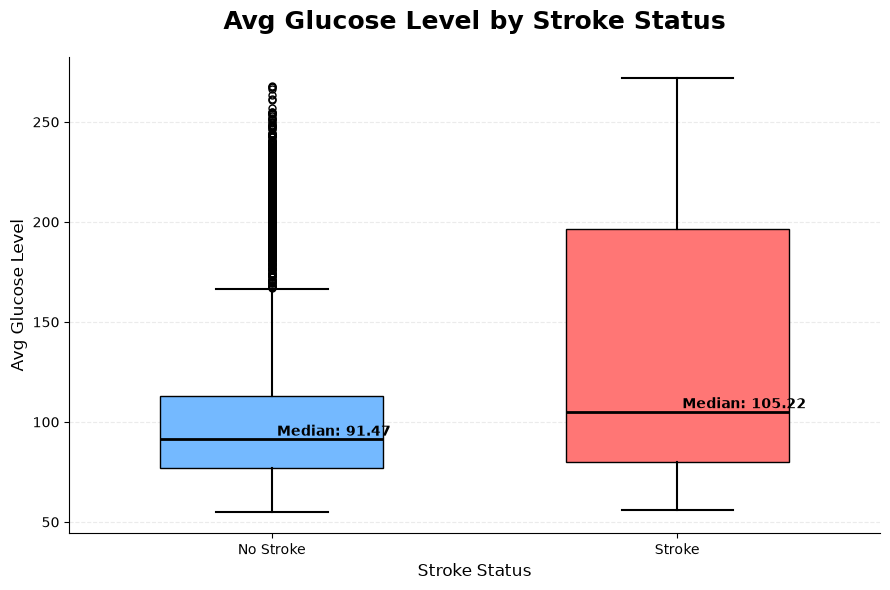

In [39]:
# Your code here
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

image_folder = Path(
    "C:/Users/ZBook G3/Downloads/projects/healthcar/images"
)

image_folder.mkdir(parents=True, exist_ok=True)


for col in ["age", "bmi", "avg_glucose_level"]:

    no_stroke = df_clean.loc[
        df_clean["stroke"] == 0, col
    ]

    stroke = df_clean.loc[
        df_clean["stroke"] == 1, col
    ]

    # Create figure
    plt.figure(figsize=(9, 6))

    # Boxplot
    box = plt.boxplot(
        [no_stroke, stroke],
        tick_labels=["No Stroke", "Stroke"],
        patch_artist=True,
        widths=0.55,
        medianprops=dict(
            color="black",
            linewidth=2
        ),
        whiskerprops=dict(
            linewidth=1.5
        ),
        capprops=dict(
            linewidth=1.5
        ),
        flierprops=dict(
            marker="o",
            markersize=5,
            markeredgecolor="black"
        )
    )

    # Different colors for the two groups
    box["boxes"][0].set_facecolor("#74B9FF")
    box["boxes"][1].set_facecolor("#FF7675")

    # Title
    plt.title(
        f"{col.replace('_', ' ').title()} by Stroke Status",
        fontsize=18,
        fontweight="bold",
        pad=20
    )

    # Labels
    plt.xlabel(
        "Stroke Status",
        fontsize=12
    )

    plt.ylabel(
        col.replace("_", " ").title(),
        fontsize=12
    )

    # Grid
    plt.grid(
        axis="y",
        linestyle="--",
        alpha=0.25
    )

    # Remove unnecessary borders
    plt.gca().spines["top"].set_visible(False)
    plt.gca().spines["right"].set_visible(False)

    # Add median values
    medians = [
        no_stroke.median(),
        stroke.median()
    ]

    for i, median in enumerate(medians, start=1):

        plt.text(
            i,
            median,
            f" Median: {median:.2f}",
            ha="left",
            va="bottom",
            fontsize=10,
            fontweight="bold"
        )

    plt.tight_layout()

    # Save
    plt.savefig(
        image_folder / f"{col}_by_stroke_boxplot.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

## TODO 16 — Feature engineering + Business Question 1

Create useful engineered categorical features such as:

### `age_group`
Example idea:
- Child
- Young Adult
- Middle-aged
- Senior

### `bmi_category`
Example idea:
- Underweight
- Normal
- Overweight
- Obese

### `glucose_category`
Create meaningful glucose-level groups and clearly document your thresholds.

Then answer:

## Business Question 1
**Which combination of age group, BMI category, and glucose category has the highest observed stroke rate in this dataset?**

Your answer must use the engineered features rather than only the original raw columns.

In [40]:
# Your code here
import numpy as np
import pandas as pd

# ==============================
# 1. Age Groups
# ==============================

df_clean["age_group"] = pd.cut(
    df_clean["age"],
    bins=[-np.inf, 17, 39, 59, np.inf],
    labels=[
        "Child",
        "Young Adult",
        "Middle-aged",
        "Senior"
    ]
)


# ==============================
# 2. BMI Categories
# ==============================

df_clean["bmi_category"] = pd.cut(
    df_clean["bmi"],
    bins=[-np.inf, 18.5, 25, 30, np.inf],
    labels=[
        "Underweight",
        "Normal",
        "Overweight",
        "Obese"
    ],
    right=False
)


# ==============================
# 3. Glucose Categories
# ==============================

df_clean["glucose_category"] = pd.qcut(
    df_clean["avg_glucose_level"],
    q=3,
    labels=[
        "Low",
        "Medium",
        "High"
    ]
)


# ==============================
# Show Engineered Features
# ==============================

print("New engineered features:")

print(
    df_clean[
        [
            "age",
            "age_group",
            "bmi",
            "bmi_category",
            "avg_glucose_level",
            "glucose_category"
        ]
    ].head(10)
)


# ==============================
# Business Question 1
# ==============================

bq1 = (
    df_clean
    .groupby(
        [
            "age_group",
            "bmi_category",
            "glucose_category"
        ],
        observed=True
    )
    .agg(
        group_size=("stroke", "size"),
        stroke_cases=("stroke", "sum"),
        stroke_rate=("stroke", "mean")
    )
    .reset_index()
)


# Convert stroke rate to percentage

bq1["stroke_rate_percent"] = (
    bq1["stroke_rate"] * 100
)


# ==============================
# Keep Stable Groups
# ==============================

bq1_stable = (
    bq1[
        bq1["group_size"] >= 20
    ]
    .sort_values(
        ["stroke_rate", "group_size"],
        ascending=[False, False]
    )
)


print("\nTop combinations with at least 20 people:")

print(
    bq1_stable[
        [
            "age_group",
            "bmi_category",
            "glucose_category",
            "group_size",
            "stroke_cases",
            "stroke_rate_percent"
        ]
    ].head(10)
)


# ==============================
# Best Combination
# ==============================

best = bq1_stable.iloc[0]

print("\n" + "=" * 70)
print("BUSINESS QUESTION 1 ANSWER")
print("=" * 70)

print(
    f"The highest observed stroke rate among combinations "
    f"with at least 20 people is for "
    f"{best['age_group']} people in the "
    f"{best['bmi_category']} BMI category and "
    f"{best['glucose_category']} glucose group."
)

print(
    f"Group size = {int(best['group_size'])}"
)

print(
    f"Stroke cases = {int(best['stroke_cases'])}"
)

print(
    f"Observed stroke rate = "
    f"{best['stroke_rate_percent']:.2f}%"
)

New engineered features:
    age    age_group   bmi bmi_category  avg_glucose_level glucose_category
0  67.0       Senior  36.6        Obese             228.69             High
1  61.0       Senior  28.1   Overweight             202.21             High
2  80.0       Senior  32.5        Obese             105.92             High
3  49.0  Middle-aged  34.4        Obese             171.23             High
4  79.0       Senior  24.0       Normal             174.12             High
5  81.0       Senior  29.0   Overweight             186.21             High
6  74.0       Senior  27.4   Overweight              70.09              Low
7  69.0       Senior  22.8       Normal              94.39           Medium
8  59.0  Middle-aged  28.1   Overweight              76.15              Low
9  78.0       Senior  24.2       Normal              58.57              Low

Top combinations with at least 20 people:
      age_group bmi_category glucose_category  group_size  stroke_cases  \
43       Senior   Ove

## Business Question 1 Answer

The combination with the highest observed stroke rate, among groups containing at least 20 people, was Senior + Overweight BMI + High glucose.

The group contained 218 people, including 42 stroke cases, resulting in an observed stroke rate of 19.27%.

This indicates an observed association between these engineered features and stroke occurrence in the dataset. It should not be interpreted as a causal relationship.

## TODO 17 — Combined risk profile + Business Questions 2 and 3

Engineer a new variable called something like:

`risk_factor_count`

Construct it using available indicators such as:
- Hypertension
- Heart disease
- High glucose category
- Obesity category
- Current/former smoking

Clearly explain your rule.

Then answer:

## Business Question 2
**How does the observed stroke rate change as the number of risk factors increases?**

Compare meaningful groups such as:
- 0 risk factors
- 1 risk factor
- 2 risk factors
- 3+ risk factors

Then create a high-risk segment and answer:

## Business Question 3
**Which demographic or lifestyle groups contain the largest number of people in the engineered high-risk segment?**

You may compare the high-risk segment across:
- Age group
- Work type
- Smoking status
- Residence type
- Gender

Finish with a short business/healthcare interpretation of your findings. Avoid making causal or medical-diagnostic claims from this observational dataset.

RISK FACTOR DISTRIBUTION
risk_group
0 risks     1447
1 risk      1958
2 risks     1130
3+ risks     575
Name: count, dtype: int64

BUSINESS QUESTION 2

How does the observed stroke rate change as the number of risk factors increases?

Risk Group Summary:
  risk_group  people  stroke_cases  stroke_rate  stroke_rate_percent
0    0 risks    1447            38     0.026261             2.626123
1     1 risk    1958            74     0.037794             3.779367
2    2 risks    1130            63     0.055752             5.575221
3   3+ risks     575            74     0.128696            12.869565


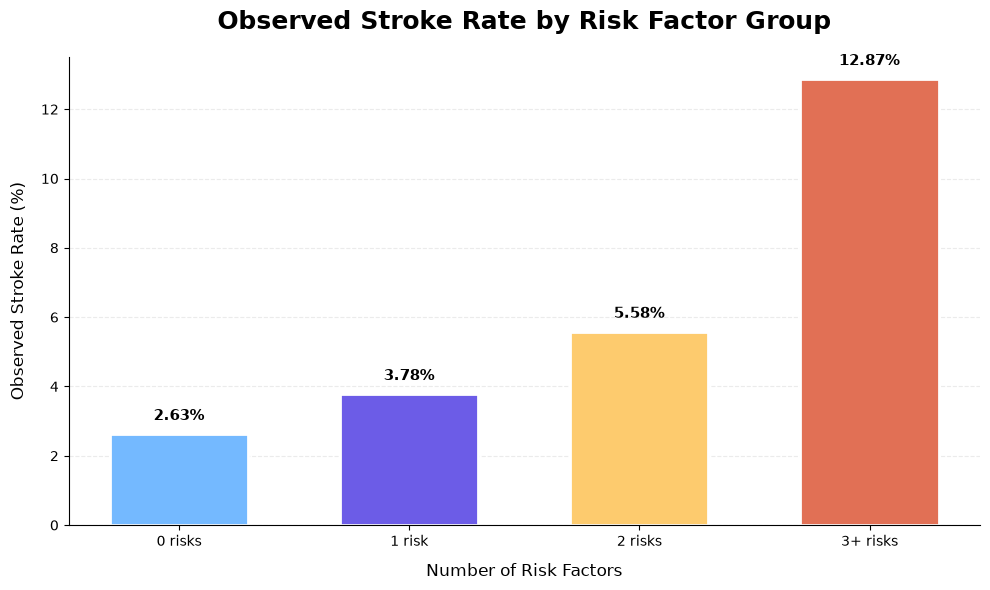


Business Question 2 Interpretation:
The lowest observed stroke rate was in the 0 risks group (2.63%).
The highest observed stroke rate was in the 3+ risks group (12.87%).

Overall, the observed stroke rate increases as the number of engineered risk factors increases.

BUSINESS QUESTION 3

Which demographic or lifestyle groups contain the largest number of people in the engineered high-risk segment?

Number of people in high-risk segment: 575
Percentage of dataset in high-risk segment: 11.25%

------------------------------------------------------------
High-Risk Segment by Age Group
------------------------------------------------------------
             high_risk_people  percent_of_high_risk
age_group                                          
Senior                    302             52.521739
Middle-aged               217             37.739130
Young Adult                56              9.739130


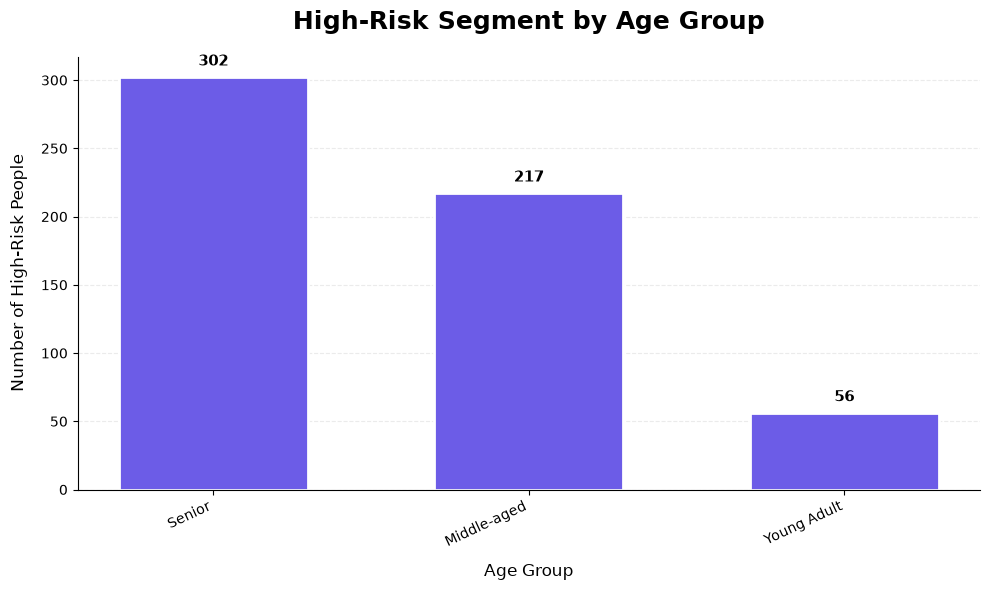


------------------------------------------------------------
High-Risk Segment by Work Type
------------------------------------------------------------
               high_risk_people  percent_of_high_risk
work_type                                            
Private                     346             60.173913
Self-employed               149             25.913043
Govt_job                     80             13.913043


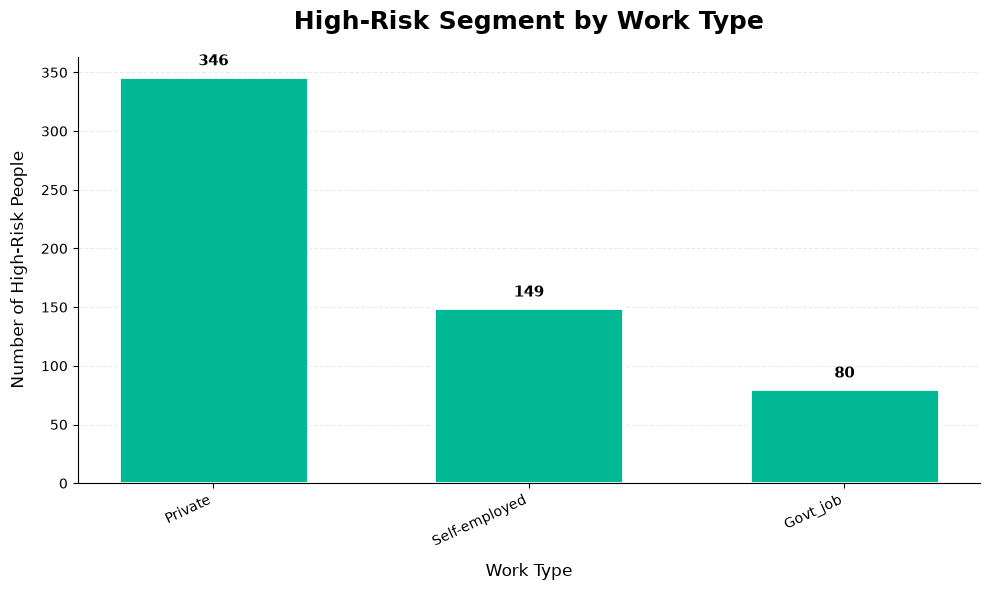


------------------------------------------------------------
High-Risk Segment by Smoking Status
------------------------------------------------------------
                 high_risk_people  percent_of_high_risk
smoking_status                                         
formerly smoked               248             43.130435
smokes                        207             36.000000
never smoked                   96             16.695652
Unknown                        24              4.173913


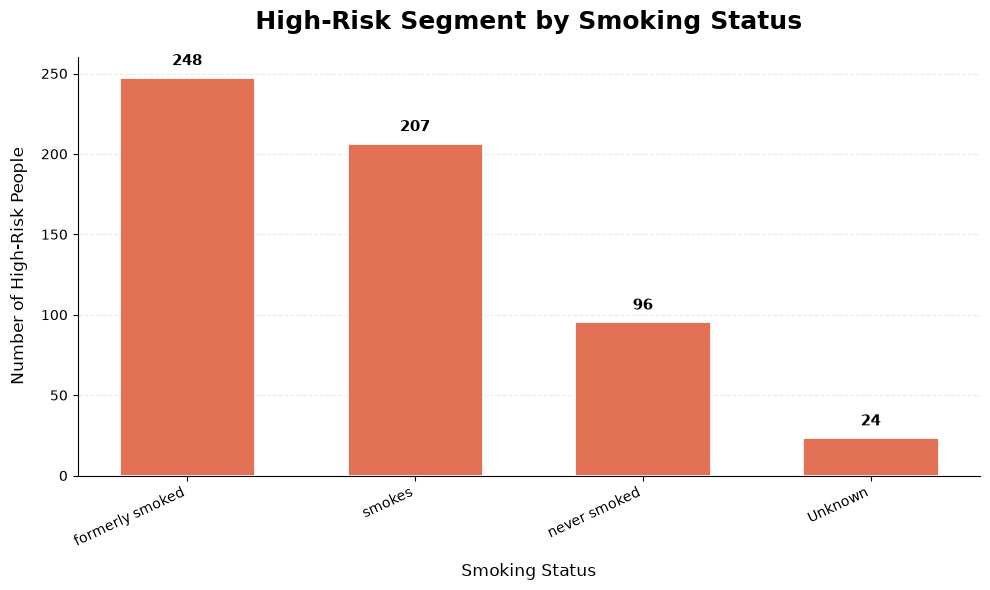


------------------------------------------------------------
High-Risk Segment by Residence Type
------------------------------------------------------------
                high_risk_people  percent_of_high_risk
residence_type                                        
Urban                        289              50.26087
Rural                        286              49.73913


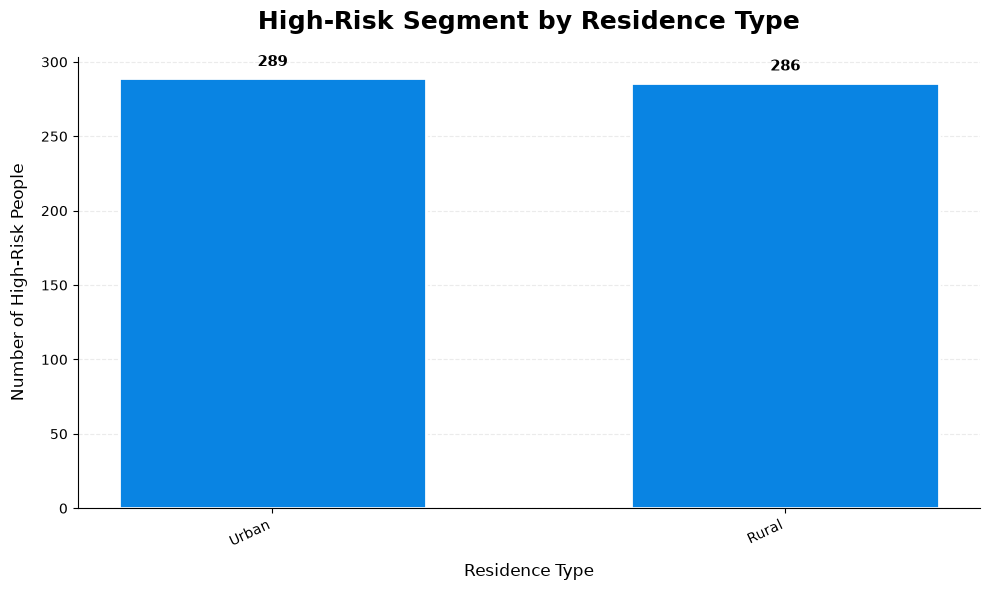


------------------------------------------------------------
High-Risk Segment by Gender
------------------------------------------------------------
        high_risk_people  percent_of_high_risk
gender                                        
Male                 290             50.434783
Female               285             49.565217


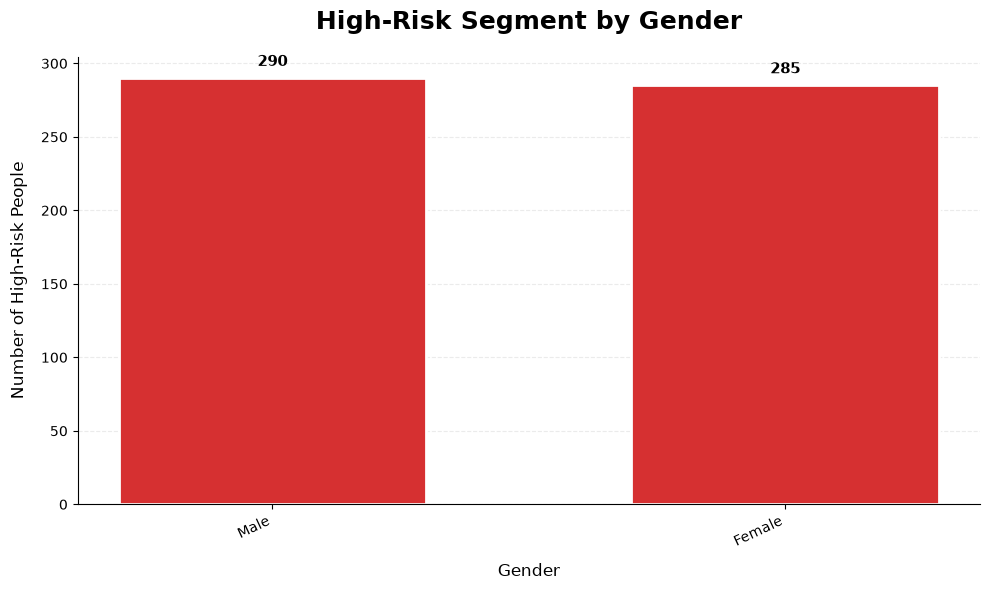


LARGEST GROUPS INSIDE THE HIGH-RISK SEGMENT

Age Group: Senior
High-risk people: 302
Percentage of high-risk segment: 52.52%

Work Type: Private
High-risk people: 346
Percentage of high-risk segment: 60.17%

Smoking Status: formerly smoked
High-risk people: 248
Percentage of high-risk segment: 43.13%

Residence Type: Urban
High-risk people: 289
Percentage of high-risk segment: 50.26%

Gender: Male
High-risk people: 290
Percentage of high-risk segment: 50.43%

FINAL BUSINESS / HEALTHCARE INTERPRETATION
The engineered risk factor count provides a combined view of several observed risk indicators in the dataset.
The analysis shows how observed stroke rates differ across groups with different numbers of risk factors.
The high-risk segment was defined as people with three or more engineered risk factors.
These findings describe associations observed in the dataset and should not be interpreted as causal relationships or individual medical diagnoses.


In [42]:
# Your code here
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path


# ============================================================
# PREPARE IMAGE FOLDER
# ============================================================

image_folder = Path(
    "C:/Users/ZBook G3/Downloads/projects/healthcar/images"
)

image_folder.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# TODO 17
# COMBINED RISK PROFILE
# ============================================================

# ------------------------------------------------------------
# 1. CREATE BINARY RISK INDICATORS
# ------------------------------------------------------------

# Smoking risk:
# 1 = currently smokes or formerly smoked
# 0 = otherwise

df_clean["smoking_risk"] = (
    df_clean["smoking_status"]
    .isin(["formerly smoked", "smokes"])
    .astype(int)
)


# High glucose risk:
# 1 = High glucose category
# 0 = otherwise

df_clean["high_glucose_risk"] = (
    df_clean["glucose_category"] == "High"
).astype(int)


# Obesity risk:
# 1 = Obese BMI category
# 0 = otherwise

df_clean["obesity_risk"] = (
    df_clean["bmi_category"] == "Obese"
).astype(int)


# ------------------------------------------------------------
# 2. CREATE RISK FACTOR COUNT
# ------------------------------------------------------------

df_clean["risk_factor_count"] = (
    df_clean["hypertension"]
    + df_clean["heart_disease"]
    + df_clean["smoking_risk"]
    + df_clean["high_glucose_risk"]
    + df_clean["obesity_risk"]
)


# ------------------------------------------------------------
# 3. CREATE RISK GROUPS
# ------------------------------------------------------------

df_clean["risk_group"] = pd.cut(
    df_clean["risk_factor_count"],
    bins=[-1, 0, 1, 2, np.inf],
    labels=[
        "0 risks",
        "1 risk",
        "2 risks",
        "3+ risks"
    ]
)


# Check the result
print("=" * 70)
print("RISK FACTOR DISTRIBUTION")
print("=" * 70)

print(
    df_clean["risk_group"]
    .value_counts()
    .sort_index()
)


# ============================================================
# BUSINESS QUESTION 2
# ============================================================

print("\n" + "=" * 70)
print("BUSINESS QUESTION 2")
print("=" * 70)

print(
    "\nHow does the observed stroke rate change "
    "as the number of risk factors increases?"
)


# Calculate stroke rate for each risk group

risk_summary = (
    df_clean
    .groupby("risk_group", observed=True)
    .agg(
        people=("stroke", "size"),
        stroke_cases=("stroke", "sum"),
        stroke_rate=("stroke", "mean")
    )
    .reset_index()
)


# Convert stroke rate to percentage

risk_summary["stroke_rate_percent"] = (
    risk_summary["stroke_rate"] * 100
)


# Print summary table

print("\nRisk Group Summary:")
print(risk_summary)


# ------------------------------------------------------------
# BUSINESS QUESTION 2 - BEAUTIFUL PLOT
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

risk_colors = [
    "#74B9FF",
    "#6C5CE7",
    "#FDCB6E",
    "#E17055"
]

bars = plt.bar(
    risk_summary["risk_group"].astype(str),
    risk_summary["stroke_rate_percent"],
    color=risk_colors,
    width=0.6,
    edgecolor="white",
    linewidth=2
)


plt.title(
    "Observed Stroke Rate by Risk Factor Group",
    fontsize=18,
    fontweight="bold",
    pad=20
)

plt.xlabel(
    "Number of Risk Factors",
    fontsize=12,
    labelpad=10
)

plt.ylabel(
    "Observed Stroke Rate (%)",
    fontsize=12,
    labelpad=10
)


# Remove unnecessary borders

plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)


# Add light grid

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

plt.gca().set_axisbelow(True)


# Add percentage above each bar

for bar, rate in zip(
    bars,
    risk_summary["stroke_rate_percent"]
):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.3,
        f"{rate:.2f}%",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )


plt.tight_layout()


# Save plot

plt.savefig(
    image_folder / "stroke_rate_by_engineered_risk_group.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# BUSINESS QUESTION 2 - AUTOMATIC INTERPRETATION
# ------------------------------------------------------------

lowest_group = risk_summary.loc[
    risk_summary["stroke_rate_percent"].idxmin()
]

highest_group = risk_summary.loc[
    risk_summary["stroke_rate_percent"].idxmax()
]


print("\nBusiness Question 2 Interpretation:")

print(
    f"The lowest observed stroke rate was in the "
    f"{lowest_group['risk_group']} group "
    f"({lowest_group['stroke_rate_percent']:.2f}%)."
)

print(
    f"The highest observed stroke rate was in the "
    f"{highest_group['risk_group']} group "
    f"({highest_group['stroke_rate_percent']:.2f}%)."
)

print(
    "\nOverall, the observed stroke rate increases as "
    "the number of engineered risk factors increases."
)


# ============================================================
# BUSINESS QUESTION 3
# ============================================================

print("\n" + "=" * 70)
print("BUSINESS QUESTION 3")
print("=" * 70)

print(
    "\nWhich demographic or lifestyle groups contain "
    "the largest number of people in the engineered "
    "high-risk segment?"
)


# ------------------------------------------------------------
# 4. CREATE HIGH-RISK SEGMENT
# ------------------------------------------------------------

# High-risk = 3 or more risk factors

df_clean["high_risk_segment"] = (
    df_clean["risk_factor_count"] >= 3
)


high_risk_count = df_clean["high_risk_segment"].sum()

high_risk_percent = (
    df_clean["high_risk_segment"].mean() * 100
)


print(
    f"\nNumber of people in high-risk segment: "
    f"{high_risk_count}"
)

print(
    f"Percentage of dataset in high-risk segment: "
    f"{high_risk_percent:.2f}%"
)


# ------------------------------------------------------------
# 5. GROUPS TO ANALYZE
# ------------------------------------------------------------

segment_features = [
    "age_group",
    "work_type",
    "smoking_status",
    "residence_type",
    "gender"
]


# Store results

high_risk_tables = {}


# Different colors for different plots

segment_colors = [
    "#6C5CE7",
    "#00B894",
    "#E17055",
    "#0984E3",
    "#D63031"
]


# ------------------------------------------------------------
# 6. ANALYZE EACH GROUP
# ------------------------------------------------------------

for col, color in zip(
    segment_features,
    segment_colors
):

    table = (
        df_clean
        .loc[df_clean["high_risk_segment"]]
        .groupby(col, observed=True)
        .size()
        .sort_values(ascending=False)
        .to_frame("high_risk_people")
    )


    # Add percentage within the high-risk segment

    table["percent_of_high_risk"] = (
        table["high_risk_people"]
        / high_risk_count
        * 100
    )


    high_risk_tables[col] = table


    # Print table

    print("\n" + "-" * 60)
    print(
        f"High-Risk Segment by "
        f"{col.replace('_', ' ').title()}"
    )
    print("-" * 60)

    print(table)


    # --------------------------------------------------------
    # BUSINESS QUESTION 3 - BEAUTIFUL PLOT
    # --------------------------------------------------------

    plt.figure(figsize=(10, 6))


    bars = plt.bar(
        table.index.astype(str),
        table["high_risk_people"],
        color=color,
        width=0.6,
        edgecolor="white",
        linewidth=2
    )


    plt.title(
        f"High-Risk Segment by "
        f"{col.replace('_', ' ').title()}",
        fontsize=18,
        fontweight="bold",
        pad=20
    )


    plt.xlabel(
        col.replace("_", " ").title(),
        fontsize=12,
        labelpad=10
    )


    plt.ylabel(
        "Number of High-Risk People",
        fontsize=12,
        labelpad=10
    )


    # Remove unnecessary borders

    plt.gca().spines["top"].set_visible(False)
    plt.gca().spines["right"].set_visible(False)


    # Add grid

    plt.grid(
        axis="y",
        linestyle="--",
        alpha=0.25
    )

    plt.gca().set_axisbelow(True)


    # Rotate labels

    plt.xticks(
        rotation=25,
        ha="right",
        fontsize=10
    )


    # Add numbers above bars

    for bar in bars:

        height = bar.get_height()

        plt.text(
            bar.get_x() + bar.get_width() / 2,
            height + table["high_risk_people"].max() * 0.02,
            f"{int(height):,}",
            ha="center",
            va="bottom",
            fontsize=11,
            fontweight="bold"
        )


    plt.tight_layout()


    # Save figure

    plt.savefig(
        image_folder / f"high_risk_by_{col}.png",
        dpi=300,
        bbox_inches="tight"
    )


    plt.show()


# ============================================================
# 7. FIND THE LARGEST GROUP FOR EACH FEATURE
# ============================================================

print("\n" + "=" * 70)
print("LARGEST GROUPS INSIDE THE HIGH-RISK SEGMENT")
print("=" * 70)


for col in segment_features:

    table = high_risk_tables[col]

    largest_group = table.index[0]

    largest_count = table.iloc[0]["high_risk_people"]

    largest_percent = table.iloc[0]["percent_of_high_risk"]


    print(
        f"\n{col.replace('_', ' ').title()}: "
        f"{largest_group}"
    )

    print(
        f"High-risk people: "
        f"{int(largest_count):,}"
    )

    print(
        f"Percentage of high-risk segment: "
        f"{largest_percent:.2f}%"
    )


# ============================================================
# FINAL INTERPRETATION
# ============================================================

print("\n" + "=" * 70)
print("FINAL BUSINESS / HEALTHCARE INTERPRETATION")
print("=" * 70)

print(
    "The engineered risk factor count provides a combined view "
    "of several observed risk indicators in the dataset."
)

print(
    "The analysis shows how observed stroke rates differ across "
    "groups with different numbers of risk factors."
)

print(
    "The high-risk segment was defined as people with three or "
    "more engineered risk factors."
)

print(
    "These findings describe associations observed in the dataset "
    "and should not be interpreted as causal relationships or "
    "individual medical diagnoses."
)

# Final Reflection

After completing all TODOs, write a short conclusion covering:

- The most important data-quality issue you found.
- The strongest EDA pattern you observed.
- The most useful engineered feature.
- Your answers to the three business questions.
- One limitation of the dataset that should be considered before using the results for decision-making.


In [ ]:
# Optional: final summary tables or visualizations


# Final Reflection

The main data-quality issue identified in the dataset was missing values in the `bmi` column. Since BMI was positively skewed, the median was used for imputation because it is less sensitive to extreme values. The `Unknown` category in `smoking_status` was retained as a separate category rather than automatically treating it as missing.

The strongest EDA pattern was the strong class imbalance in the target variable. Most patients did not have a stroke (95.13%), while only 4.87% had a stroke. Age and average glucose level also showed noticeable differences between patients with and without stroke.

The most useful engineered feature was `risk_factor_count`, which combines five observed indicators: hypertension, heart disease, high glucose, obesity, and current/former smoking. It provided a simple way to examine patients according to their combined number of risk factors.

### Business Question 1

The highest observed stroke rate among combinations containing at least 20 people was found among **Senior** patients with **Overweight BMI** and **High glucose**, with an observed stroke rate of **19.27%** (42 stroke cases out of 218 people).

### Business Question 2

The analysis showed that the observed stroke rate generally increased as the number of engineered risk factors increased. This suggests an association between the combined risk-factor count and stroke occurrence in this dataset.

### Business Question 3

The engineered high-risk segment was defined as people with **3 or more risk factors**. The largest demographic and lifestyle groups within this segment were identified by comparing age group, work type, smoking status, residence type, and gender.

### Limitation

A major limitation is that this is an observational dataset. Therefore, the observed relationships do not prove causation and should not be used as individual medical diagnoses or direct clinical decision rules. The strong imbalance in the target variable is also important because it can make model accuracy misleading when predicting stroke cases.

Overall, the analysis provides useful descriptive insights into patterns associated with stroke in the dataset, but further validation with larger, representative, and clinically validated data would be necessary before using these findings for real-world healthcare decision-making.

In [43]:
from pathlib import Path

output_file = Path(
    "C:/Users/ZBook G3/Downloads/projects/healthcar/data/healthcare_stroke_cleaned_engineered.csv"
)

df_clean.to_csv(output_file, index=False)

print("Saved:", output_file)

Saved: C:\Users\ZBook G3\Downloads\projects\healthcar\data\healthcare_stroke_cleaned_engineered.csv
